# Стоимость оперативной памяти (платим только за гигабайты?)

## 1.Описание данных

<font size="4">

Описание признаков

1. `id` - идентификатор строки, не несет полезной информации для предсказания и удаляется перед моделированием<br>
2. `capacity_gb` - объем модуля памяти в ГБ (4-128)<br>
3. `clock_speed_mhz` - тактовая частота памяти в МГц<br>
4. `cas_latency` - задержка CAS; меньшее значение означает более быстрый отклик<br>
5. `release_year` - год выпуска модуля<br>
6. `warranty_years` - срок гарантии производителя в годах<br>
7. `ram_type` - тип оперативной памяти: DDR3 / DDR4 / DDR5<br>
8. `brand` - производитель модуля: Corsair / Kingston / G.Skill / Crucial<br>
9. `form_factor` - форм-фактор модуля: DIMM / SO-DIMM<br>
10. `use_case` - сценарий использования: Gaming / Server / Laptop<br>
11. `rgb_lighting` - наличие RGB-подсветки: `0` - нет, `1` - есть<br>
12. `heatsink_included` - наличие радиатора: `0` - нет, `1` - есть<br>
13. `price_usd` - целевая переменная 🎯, цена модуля в USD

Ссылка на датасет с kaggle: [RAM Price Prediction Dataset](https://www.kaggle.com/datasets/abacilla/ram-price-prediction-dataset)

Задача: регрессия

</font>

## 2.Вопросы исследования

<font size="4">

- Вопрос 1. Дешевеет ли гигабайт памяти при покупке модуля большего объёма, и какая часть цены модуля зависит от объёма, а какая - нет?
- Вопрос 2. Насколько дороже обходится переход на новое поколение памяти (DDR4 -> DDR5) и одинакова ли эта переплата для модулей разного объёма?
- Вопрос 3. Что важнее для цены - объём модуля или его "современность" (поколение, частота, год выпуска)?

</font>

## 3.Первичный анализ

<font size="4">

### Импорт библиотек и загрузка датасета

</font>

In [ ]:
!pip install pyampute -q

In [ ]:
# Стандарт
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

# доп., для красоты
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# для анализа пропусков
from scipy.stats import chi2_contingency, mannwhitneyu
from scipy.stats.contingency import association
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.tools import add_constant
from pyampute.exploration.mcar_statistical_tests import MCARTest

# Предобработка и Pipline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.model_selection import train_test_split

# с гитхаба, на случай если пропадут на kaggle
df = pd.read_csv('https://github.com/STEPANPROTSKY/MLandDA/raw/main/Datasets/ram_price_prediction_dataset.csv')

<font size="4">

### Структура и дубликаты

</font>

In [ ]:
df.head()

,id,capacity_gb,clock_speed_mhz,cas_latency,release_year,warranty_years,ram_type,brand,form_factor,use_case,rgb_lighting,heatsink_included,price_usd
0,40952,32,5570.0,28,2024,5,DDR5,G.Skill,DIMM,Gaming,0.0,0,221.33
1,5772,32,5730.0,25,2022,5,DDR5,Kingston,SO-DIMM,Gaming,0.0,0,210.61
2,16578,8,5080.0,28,2024,5,DDR5,Crucial,SO-DIMM,Gaming,0.0,1,113.20
3,30602,4,5310.0,31,2022,10,DDR5,G.Skill,SO-DIMM,Gaming,NaN,0,122.01
4,33648,32,2920.0,18,2015,2,DDR4,Crucial,SO-DIMM,Server,1.0,0,141.44


In [ ]:
df_ = df.copy()
df_.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58000 entries, 0 to 57999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 58000 non-null  int64  
 1   capacity_gb        58000 non-null  int64  
 2   clock_speed_mhz    55689 non-null  float64
 3   cas_latency        58000 non-null  int64  
 4   release_year       58000 non-null  int64  
 5   warranty_years     58000 non-null  int64  
 6   ram_type           58000 non-null  object 
 7   brand              58000 non-null  object 
 8   form_factor        58000 non-null  object 
 9   use_case           56825 non-null  object 
 10  rgb_lighting       53945 non-null  float64
 11  heatsink_included  58000 non-null  int64  
 12  price_usd          58000 non-null  float64
dtypes: float64(3), int64(6), object(4)
memory usage: 5.8+ MB


<font size="4">

Датасет размером 58000 х 13, уже видно, что есть пропущенные значения (по признакам `clock_speed_mhz`, `use_case`, `rgb_lighting`)

</font>

<font size="4">

Первым делом проверяем данные на полные дубликаты (строки, совпадающие по всем столбцам) и удаляем их, потому что дубликаты: искажают статистику, завышают уверенность в выводах, приводят к утечке данных и не несут новой информации

</font>

In [ ]:
# смотрим дубли
df_.duplicated().sum()

np.int64(8000)

<font size="4">
    
Имеется 8000 полных дубликатов от них смело избавляемся

<font/>

In [ ]:
df_ = df_.drop_duplicates().reset_index(drop=True)
# заодно удалим id, за ненадобностью
df_.drop(columns='id', axis=1, inplace=True)

In [ ]:
df_.describe()

,capacity_gb,clock_speed_mhz,cas_latency,release_year,warranty_years,rgb_lighting,heatsink_included,price_usd
count,50000.000000,48000.000000,50000.000000,50000.000000,50000.000000,46500.000000,50000.000000,50000.000000
mean,27.085920,3520.569375,22.396920,2018.874940,3.797200,0.348581,0.548820,145.466799
std,25.029059,1479.623957,5.776009,3.484988,2.410914,0.476526,0.497616,86.728368
min,4.000000,1070.000000,8.000000,2012.000000,1.000000,0.000000,0.000000,8.000000
25%,16.000000,2560.000000,18.000000,2016.000000,2.000000,0.000000,0.000000,86.190000
50%,16.000000,3060.000000,22.000000,2019.000000,3.000000,0.000000,1.000000,129.580000
75%,32.000000,5090.000000,27.000000,2021.000000,5.000000,1.000000,1.000000,167.900000
max,128.000000,7950.000000,42.000000,2025.000000,10.000000,1.000000,1.000000,547.480000


<font size="4">
    
По числовым признакам (после удаления 8000 дубликатов):<br>

Общее: 50000 строк. Пропуски есть в признаках `clock_speed_mhz` (2000 пропусков, 4,0%) и `rgb_lighting` (3500 пропусков, 7,0%) остальные числовые признаки полные<br>

- `capacity_gb` сильно скошен вправо: медиана 16, среднее 27.09, максимум 128; `коэффициент асимметрии Пирсона = 3 * (mean - median) / std = 3 * (27.09 - 16) / 25.03 = ~1,33` (самый скошенный признак). Q1 = медиана = 16, значит минимум четверть значений ровно 16, а вообще признак дискретный (4, 8, 16, 32, 64, 128). По Тьюки `IQR = 32 - 16 = 16`, мягкая граница `Q3 + 1,5 * IQR = 56`, жесткая `Q3 + 3 * IQR = 80` => 64 - мягкий выброс, 128 - жесткий. Но это законные значения, удалять их нельзя, возможно стоит преобразовать по степеням двойки, тогда шаг станет равномерным<br>

- `clock_speed_mhz` медиана 3060, среднее 3520.57, максимум 7950; скошенность `3 * (3520.57- 3060) / 1479.62 = ~0,93`. От Q1 до медианы 500, от медианы до Q3 2030, при этом max всего на 2860 выше Q3 => это не редкие выбросы, а «тяжелая» верхняя половина. Граница Тьюки `5090 + 1,5 * 2530 = ~8885` выше максимума, выбросов нет<br>

- `cas_latency` медиана 22, среднее 22.40, диапазон 8-42; расстояния от Q1 до медианы (4) и от медианы до Q3 (5) почти равны, скошенность `3 * (22.40 - 22) / 5.78 = ~0,21` => распределение близко к симметричному. Границы Тьюки 4,5 и 40,5 => значения 41-42 формально выбросы, но их единицы и они правдоподобны<br>

- `release_year` медиана 2019, диапазон 2012-2025; среднее (2018.87) чуть ниже медианы, скошенность `3 * (2018.87 - 2019) / 3.48 = ~ -0,11` => слегка смещен влево, новых моделей немного больше. Выбросов нет (границы Тьюки 2008,5-2028,5). Наверное удобнее будет перейти к возрасту модели относительно 2026 года<br>

- `warranty_years` медиана 3, диапазон 1-10, среднее 3.80 => правая скошенность `3 * (3.80 - 3) / 2.41 = ~0,99`, признак дискретный. Граница Тьюки `5 + 1,5 * 3 = 9,5` => 10 лет формально выброс, но это вполне себе законное значение<br>

- `rgb_lighting` среднее 0.349 => RGB есть у 34,9% записей среди заполненных (еще 7% пропусков), а вообще категориальный (бинарный) признак<br>

- `heatsink_included` среднее 0.549 => радиатор есть у 54,9% записей, а вообще категориальный (бинарный) признак<br>

- `price_usd` медиана 129.58, среднее 145.47, максимум 547.48, минимум 8; скошенность `3 * (145.47 - 129.58) / 86.73 = ~0,55` (правый хвост умеренный, слабее, чем у `capacity_gb`). `IQR = 167.90 - 86.19 = 81.71`, `Верхн. граница по Тьюки = 167.90 + 1,5 * 81.71 = ~290` USD, все выше формально выбросы. Нижней границы нет (она уходит в минус `86.19 - 122.57 = -36.38`). При n = 50000 стандартная ошибка среднего `SE = 86.73 / sqrt(50000) = ~0,39` USD, 95% доверительный интервал для среднего `145,47 +- 1,96 * 0,39` => `~145,5 +- 0,8 USD`<br>

Странных значений нет, по типу отрицательных цен, нулевого объема или годов из будущего не обнаружено (минимальная цена 8 USD, годы 2012-2025)

</font>

<font size="4">

### Анализ пропусков

Поскольку видно, что пропуски существуют, проверим к какому типу они относятся, от этого зависит то, как они будут заполняться

Типы пропусков:

- MCAR - пропуск полностью случаен и ни от чего не зависит
- MAR - пропуск зависит от других наблюдаемых признаков (например, частоту чаще не указывают у DDR3)
- MNAR - пропуск зависит от самого пропущенного значения (например, низкую частоту не указывают специально)

План проверки:

1. Тест Литтла - общая проверка гипотезы MCAR
2. Индикаторы пропусков (1 - пропуск, 0 - значение есть). Проверяем, связан ли индикатор с другими признаками: Хи квадрат для категориальных, Манна-Уитни для числовых
3. Связь пропусков между собой - не пропадают ли значения «пачками»

Как читать результаты:

- `p <= 0.05` - MCAR отвергается или найдена связь (тогда это MAR или MNAR)
- `p > 0.05` - оснований отвергнуть MCAR нет, однако это не доказательство MCAR

Отличить MAR от MNAR статистически обычно невозможно, потому что пропущенных значений мы не видим. Здесь можно опираться только на знание предметной области

</font>

In [ ]:
def add_missing_indicators(df, cols):
    """
    Добавляет к датафрейму индикаторы пропусков

    Для каждого признака из cols создается столбец <признак>_missing:
    1 - значение пропущено, 0 - значение есть

    Параметры:
    df : pd.DataFrame
        Исходные данные (не изменяются, функция работает с копией)
    cols : list of str
        Признаки, для которых нужны индикаторы

    Возвращает:
    pd.DataFrame
        Копия df с добавленными столбцами <признак>_missingg"""
    # True/False -> 1/0, к имени добавляем _missing
    indicators = df[cols].isna().astype(int).add_suffix('_missing')

    # приклеиваем индикаторы справа (concat создает новый df)
    return pd.concat([df, indicators], axis=1)

# признаки, в которых есть пропуски
MISSING_COLS = ['rgb_lighting', 'clock_speed_mhz', 'use_case']
ALPHA = 0.05

# df_ остается без изменений для дальнейшего EDA
df_miss = add_missing_indicators(df_, MISSING_COLS)

# сколько пропусков и какая доля в каждом признаке
print(df_miss.filter(like='_missing').agg(['sum', 'mean']).T)

# строк с хотя бы одним пропуском
nan = df_.isna().any(axis=1).sum()
print(nan, (nan / df_.shape[0]) * 100)

                            sum  mean
rgb_lighting_missing     3500.0  0.07
clock_speed_mhz_missing  2000.0  0.04
use_case_missing         1000.0  0.02
6262 12.524


<font size="4">
    
Наверное, можно было бы и удалить без мук совести, а возможно можно и придумать что-нибудь, т.к. ~13% данных терять грустно(

Численные доли такие "круглые", это дает намек, что в датасет пропуски, скорее всего, внесли искусственно

<font/>

In [ ]:
def little_test(df, num_cols, cat_cols=None):
    """
    Тест Литтла на MCAR, реализация из pyampute

    H0: пропуски полностью случайны (MCAR)
    Идея: сравниваются средние признаков в группах строк с разными паттернами пропусков
    При MCAR средние в этих группах не должны отличаться

    Параметры:
    df : pd.DataFrame
        Данные с пропусками
    num_cols : list of str
        Числовые признаки (включая бинарные 0/1)
    cat_cols : list of str, optional
        Категориальные признаки. Тест принимает только числа, поэтому они переводятся в dummy.
        В строках, где категория пропущена, все ее dummy ставятся в NaN, чтобы тест видел этот пропуск

    Возвращает:
    float
        p-value теста. p <= ALPHA - MCAR отвергается; p > ALPHA - оснований отвергнуть MCAR нет
        (это не доказательство MCAR)

    Ограничения: тест предполагает примерно нормальные данные и сравнивает только средние
    """
    # числовая часть идет как есть
    parts = [df[num_cols]]

    # or [] - если cat_cols не передали
    for col in cat_cols or []:

        # категорию превращаем в набор 0/1 столбцов, первую убираем, чтобы dummy не были идеально коллинеарны
        dummies = pd.get_dummies(df[col], prefix=col, drop_first=True, dtype=float)

        # get_dummies превращает NaN в нули, поэтому возвращаем пропуск в строки, где категория не указана
        dummies.loc[df[col].isna(), :] = np.nan
        parts.append(dummies)

    # собираем все в одну числовую таблицу
    data = pd.concat(parts, axis=1)

    # готовая реализация теста Литтла из pyampute, возвращает p-value
    return MCARTest(method='little').little_mcar_test(data)


# в тест берем все числовые признаки, бинарные 0/1 и таргет: важно знать, не связаны ли пропуски с ценой
little_num_cols = ['capacity_gb', 'clock_speed_mhz', 'cas_latency', 'release_year',
                   'warranty_years', 'rgb_lighting', 'heatsink_included', 'price_usd']

p_little = little_test(df_, little_num_cols, cat_cols=['use_case'])

print(f'Тест Литтла: p-value = {p_little:.4f}')
if p_little <= ALPHA:
    print('MCAR отвергается: пропуски не полностью случайны (MAR или MNAR)')
else:
    print('Оснований отвергнуть MCAR нет (но и доказательством MCAR это не является)')

Тест Литтла: p-value = 0.5654
Оснований отвергнуть MCAR нет (но и доказательством MCAR это не является)


<font size="4">

Тест Литтла: `p = 0.5654 > 0.05`, поэтому оснований отвергнуть гипотезу MCAR нет. Средние признаков в группах строк с разными паттернами пропусков статистически не различаются

Это не доказательство MCAR. К тому же тест предполагает нормальность и сравнивает только средние, а у нас признаки дискретные и мультимодальные (на графиках будет видно). Поэтому дальше проверяем связь каждого пропуска с признаками по отдельности

</font>

In [ ]:
def chi2_missing_test(df, missing_col, cat_col):
    """
    Критерий хи квадрат: связан ли пропуск в missing_col с категориальным признаком cat_col

    H0: доля пропусков в missing_col одинакова во всех категориях cat_col
    Размер эффекта - V Крамера (0 - связи нет, 1 - полная связь)
    Он нужен потому, что при большом n даже ничтожная связь дает маленький p-value

    Параметры:
    df : pd.DataFrame
        Данные с индикаторами пропусков (после add_missing_indicators)
    missing_col : str
        Признак с пропусками (берется его индикатор <missing_col>_missing)
    cat_col : str
        Категориальный признак, с которым проверяем связь

    Возвращает:
    dict или None
        Словарь с p-value и V Крамера; None, если таблица вырождена (меньше 2 строк или столбцов)
    """
    # таблица сопряженности «категория × пропуск»; строки с NaN в cat_col crosstab отбрасывает сам
    table = pd.crosstab(df[cat_col], df[f'{missing_col}_missing'])

    # для теста нужна хотя бы таблица 2×2 (две категории и обе группы: с пропуском и без)
    if table.shape[0] < 2 or table.shape[1] < 2:
        return None

    # готовый критерий хи квадрат из scipy
    chi2, p_value, dof, expected = chi2_contingency(table)

    # готовый V Крамера из scipy.stats.contingency
    cramers_v = association(table, method='cramer')

    return {'missing': missing_col, 'feature': cat_col, 'test': 'chi2',
            'p_value': p_value, 'effect': cramers_v, 'effect_metric': "Cramér's V"}


def mannwhitney_missing_test(df, missing_col, num_col):
    """
    Критерий Манна–Уитни: отличается ли num_col в строках с пропуском в missing_col и без него

    H0: распределения num_col в двух группах одинаковы
    Выбран вместо t-теста, потому что распределения признаков ненормальные
    Размер эффекта - ранговая бисериальная корреляция r = 2U / (n1 * n2) - 1 (от -1 до 1, 0 - различий нет)
    В scipy готовой функции для нее нет, поэтому считаем по формуле из U-статистики
    Знак: r < 0 - в строках с пропуском значения num_col чаще больше

    Параметры:
    df : pd.DataFrame
        Данные с индикаторами пропусков
    missing_col : str
        Признак с пропусками
    num_col : str
        Числовой признак, распределения которого сравниваем

    Возвращает:
    dict или None
        Словарь с p-value и r; None, если одна из групп пустая
    """
    # маска строк, где missing_col пропущен
    is_missing = df[f'{missing_col}_missing'] == 1

    # значения num_col там, где missing_col пропущен
    group_missing = df.loc[is_missing, num_col].dropna()

    # значения num_col там, где missing_col есть (NaN в самом num_col убираем)
    group_observed = df.loc[~is_missing, num_col].dropna()

    # группа может оказаться пустой, если два признака всегда пропадают вместе
    if len(group_observed) == 0 or len(group_missing) == 0:
        return None

    # готовый критерий из scipy; two-sided - ищем различие в любую сторону
    u_stat, p_value = mannwhitneyu(group_observed, group_missing, alternative='two-sided')

    # ранговая бисериальная корреляция из U-статистики
    r = 2 * u_stat / (len(group_observed) * len(group_missing)) - 1

    return {'missing': missing_col, 'feature': num_col, 'test': 'mann-whitney',
            'p_value': p_value, 'effect': r}


def run_missing_tests(df, missing_cols, cat_cols, num_cols, alpha=0.05):
    """
    Проверяет связь каждого индикатора пропуска со всеми признаками и корректирует p-value

    Для категориальных признаков используется chi2_missing_test, для числовых - mannwhitney_missing_test
    Тестов много, поэтому применяются поправки на множественные сравнения (statsmodels.multipletests):
        Бонферрони - строгая, Бенджамини-Хохберг (FDR) - мягче, контролирует долю ложных открытий

    Параметры:
    df : pd.DataFrame
        Данные с индикаторами пропусков
    missing_cols : list of str
        Признаки с пропусками
    cat_cols, num_cols : list of str
        Категориальные и числовые признаки, с которыми проверяем связь
    alpha : float
        Уровень значимости

    Возвращает:
    pd.DataFrame
        Таблица результатов (p_value, effect, p_bonf, p_fdr), отсортированная по p_value
    """
    results = []

    # перебираем признаки с пропусками
    for m_col in missing_cols:
        for col in cat_cols:

            # пропуск сам с собой не сравниваем
            if col != m_col:
                results.append(chi2_missing_test(df, m_col, col))
        for col in num_cols:

            # пропуск сам с собой не сравниваем
            if col != m_col:
                results.append(mannwhitney_missing_test(df, m_col, col))

    # выбрасываем пары, где тест не применим (функции вернули None), и собираем таблицу
    res = pd.DataFrame([r for r in results if r is not None])

    # поправка Бонферрони; [1] - массив скорректированных p-value
    res['p_bonf'] = multipletests(res['p_value'], alpha=alpha, method='bonferroni')[1]

    # поправка Бенджамини–Хохберга (FDR)
    res['p_fdr'] = multipletests(res['p_value'], alpha=alpha, method='fdr_bh')[1]

    # сверху самые значимые результаты
    return res.sort_values('p_value').reset_index(drop=True)

cat_cols = ['ram_type', 'brand', 'form_factor', 'use_case', 'heatsink_included', 'rgb_lighting']
num_cols = ['capacity_gb', 'clock_speed_mhz', 'cas_latency', 'release_year', 'warranty_years', 'price_usd']

missing_tests = run_missing_tests(df_miss, MISSING_COLS, cat_cols, num_cols)

n_tests = len(missing_tests)
print(f'Тестов: {n_tests}, ожидаемо ложных срабатываний при MCAR: {n_tests * ALPHA:.1f}')
print(f'Значимых без поправки:   {(missing_tests["p_value"] <= ALPHA).sum()}')
print(f'Значимых с Бонферрони:   {(missing_tests["p_bonf"] <= ALPHA).sum()}')
print(f'Значимых с FDR (BH):     {(missing_tests["p_fdr"] <= ALPHA).sum()}')
print(f'Максимальный |эффект|:   {missing_tests["effect"].abs().max():.3f}')

missing_tests.round(4)

Тестов: 33, ожидаемо ложных срабатываний при MCAR: 1.7
Значимых без поправки:   3
Значимых с Бонферрони:   0
Значимых с FDR (BH):     0
Максимальный |эффект|:   0.043


,missing,feature,test,p_value,effect,effect_metric,p_bonf,p_fdr
0,use_case,cas_latency,mann-whitney,0.0187,-0.0433,NaN,0.6173,0.3380
1,use_case,release_year,mann-whitney,0.0252,-0.0411,NaN,0.8323,0.3380
2,use_case,ram_type,chi2,0.0392,0.0114,Cramér's V,1.0000,0.3380
3,rgb_lighting,price_usd,mann-whitney,0.0536,-0.0195,NaN,1.0000,0.3380
4,rgb_lighting,capacity_gb,mann-whitney,0.0597,-0.0184,NaN,1.0000,0.3380
5,use_case,clock_speed_mhz,mann-whitney,0.0615,-0.0350,NaN,1.0000,0.3380
6,clock_speed_mhz,brand,chi2,0.0917,0.0114,Cramér's V,1.0000,0.4322
7,rgb_lighting,heatsink_included,chi2,0.1550,0.0064,Cramér's V,1.0000,0.5220
8,clock_speed_mhz,ram_type,chi2,0.1562,0.0086,Cramér's V,1.0000,0.5220
9,use_case,rgb_lighting,chi2,0.1582,0.0067,Cramér's V,1.0000,0.5220


<font size="4">

Из 33 тестов без поправки значимы 3, при этом даже при чистом MCAR случайно ожидается ~1.7 срабатывания. Все три связаны с `use_case_missing`:

- `cas_latency` (p = 0.019, r = -0.043)
- `release_year` (p = 0.025, r = -0.041)
- `ram_type` (p = 0.039, V = 0.011)

Признаки сильно связаны между собой, потому что все определяются поколением памяти. Знак r говорит, что в строках без `use_case` значения `cas_latency` и `release_year` чуть выше, но разница ничтожна

После поправок на множественные сравнения значимых связей не остается: минимальный p после Бонферрони = 0.617, после FDR = 0.338. Максимальный |эффект| = 0.043, что намного ниже порога 0.1. Связь пропусков с таргетом `price_usd` тоже не обнаружена (для `rgb_lighting` p = 0.054 без поправки, эффект -0.02)

Вероятность пропуска ни в одном признаке не зависит от наблюдаемых признаков, свидетельств MAR нет

</font>

In [ ]:
def missing_pairs_test(df, missing_cols):
    """
    Проверяет, связаны ли пропуски в разных признаках между собой (не пропадают ли значения «пачками»)

    Для каждой пары индикаторов строится таблица 2x2 и применяется хи квадрат
    H0: пропуски в двух признаках независимы
    Размер эффекта - коэффициент chi (для таблицы 2x2 совпадает с V Крамера)

    Параметры:
    df : pd.DataFrame
        Данные с индикаторами пропусков
    missing_cols : list of str
        Признаки с пропусками

    Возвращает:
    pd.DataFrame
        Для каждой пары: факт и ожидание числа строк, где пропущены оба признака, p-value и phi
    """
    results = []

    # все пары признаков без повторов: (a, b) без (b, a)
    for a, b in combinations(missing_cols, 2):

        # таблица 2x2: пропуск в a x пропуск в b
        table = pd.crosstab(df[f'{a}_missing'], df[f'{b}_missing'])

        # expected - частоты, которые были бы при независимых пропусках
        chi2, p_value, _, expected = chi2_contingency(table)

        results.append({
            'pair': f'{a} х {b}',

            # факт: в скольких строках пропущены оба признака
            'both_missing': table.loc[1, 1],

            # ожидание для той же ячейки при независимости
            'expected_both': round(expected[1, 1]),
            'p_value': p_value,

            # phi - это V Крамера для таблицы 2х2
            'phi': np.sqrt(chi2 / table.values.sum()),
        })

    return pd.DataFrame(results)


def rows_with_missing_check(df, missing_cols):
    """
    Сравнивает число строк хотя бы с одним пропуском с ожиданием при независимых пропусках

    Если пропуски независимы, вероятность «в строке нет ни одного пропуска» = П(1 - pi),
    где pi - доля пропусков в i-м признаке. Ожидаемое число строк с пропусками = n · (1 - ∏(1 - pi))
    Готовой функции для этого нет, поэтому считаем вручную

    Параметры:
    df : pd.DataFrame
        Данные с индикаторами пропусков
    missing_cols : list of str
        Признаки с пропусками

    Возвращает:
    tuple (int, float)
        Фактическое и ожидаемое число строк хотя бы с одним пропуском
    """
    # оставляем только столбцы-индикаторы
    indicators = df[[f'{col}_missing' for col in missing_cols]]

    # строки, где пропущено хотя бы одно значение
    observed = indicators.any(axis=1).sum()

    # mean() индикатора - это доля пропусков pi, считаем ожидание по формуле из docstring
    expected = len(df) * (1 - np.prod(1 - indicators.mean()))

    print(f'Строк хотя бы с одним пропуском: факт = {observed}, ожидание при независимости = {expected:.0f}')

display(missing_pairs_test(df_miss, MISSING_COLS).round(4))
rows_with_missing_check(df_miss, MISSING_COLS)

,pair,both_missing,expected_both,p_value,phi
0,rgb_lighting х clock_speed_mhz,131,140,0.4471,0.0034
1,rgb_lighting х use_case,80,70,0.2343,0.0053
2,clock_speed_mhz х use_case,29,40,0.0870,0.0077


Строк хотя бы с одним пропуском: факт = 6262, ожидание при независимости = 6253


<font size="4">

Для всех пар признаков фактическое число строк, где пропущены оба значения, близко к ожидаемому при независимости:

- `rgb_lighting x clock_speed_mhz`: 131 против 140, p = 0.447
- `rgb_lighting x use_case`: 80 против 70, p = 0.234
- `clock_speed_mhz x use_case`: 29 против 40, p = 0.087

phi < 0.01 во всех парах, то есть связи практически нет. Строк хотя бы с одним пропуском 6262 при ожидаемых ~6253

Значит, значения пропадают независимо друг от друга. Удаление строк с пропусками стоит ~13% данных => заполнять выгоднее, чем удалять

</font>

<font size="4">

Общий вывод по анализу пропусков

- MCAR: тест Литтла его не отвергает (p = 0.565)
- MAR: связи пропусков с наблюдаемыми признаками, в том числе с таргетом, нет. 3 значимых результата из 33 укладываются в ожидаемое число случайных срабатываний, исчезают после поправок и имеют ничтожный эффект (|эффект| <= 0.043)
- Пропуски между собой независимы: 6262 строки с пропусками против ожидаемых ~6253
- MNAR статистически отличить нельзя, потому что пропущенных значений мы не видим. Но датасет имеет "круглое" количество пропусков (3500 / 2000 / 1000), и пропуски независимы друг от друга. Это говорит о случайном внесении пропусков, так что MNAR маловероятен

В итоге данные согласуются с MCAR, свидетельств против него нет. Поэтому можно использовать простую импутацию без моделирования механизма пропусков

Стратегия заполнения (предварительно):

- `clock_speed_mhz` - медиана по `ram_type` и `release_year`, потому что частота сильно зависит от поколения памяти, а внутри поколения может растти с годом выпуска
- `use_case` - отдельная категория `'Unknown'`. При MCAR строки с пропуском - случайная смесь Gaming / Laptop / Server, поэтому модель оценит для `Unknown` средний эффект. Если заполнить модой (Gaming), часть строк получит неверную категорию, и эффект Gaming размоется.
- `rgb_lighting` - категория `0 / 1 / unknown` через OneHotEncoder, если заполнить модой (0), около 35% из 3500 строк получат неверную метку "без RGB" (~1200 строк), и эффект RGB занизится

</font>

In [ ]:
# для удобства создадим список числовых признаков, убирая признаки являющиеся бинарными (категориальными), отдельно бинарные и категориальные
num = df_.select_dtypes(include = ['int', 'float']).columns.tolist()
binary = ['rgb_lighting', 'heatsink_included']
num = [col for col in num if col not in binary]

cat = df_.select_dtypes(include=['object', 'category']).columns.tolist()

## 4.EDA

### Распределения у числовых признаков

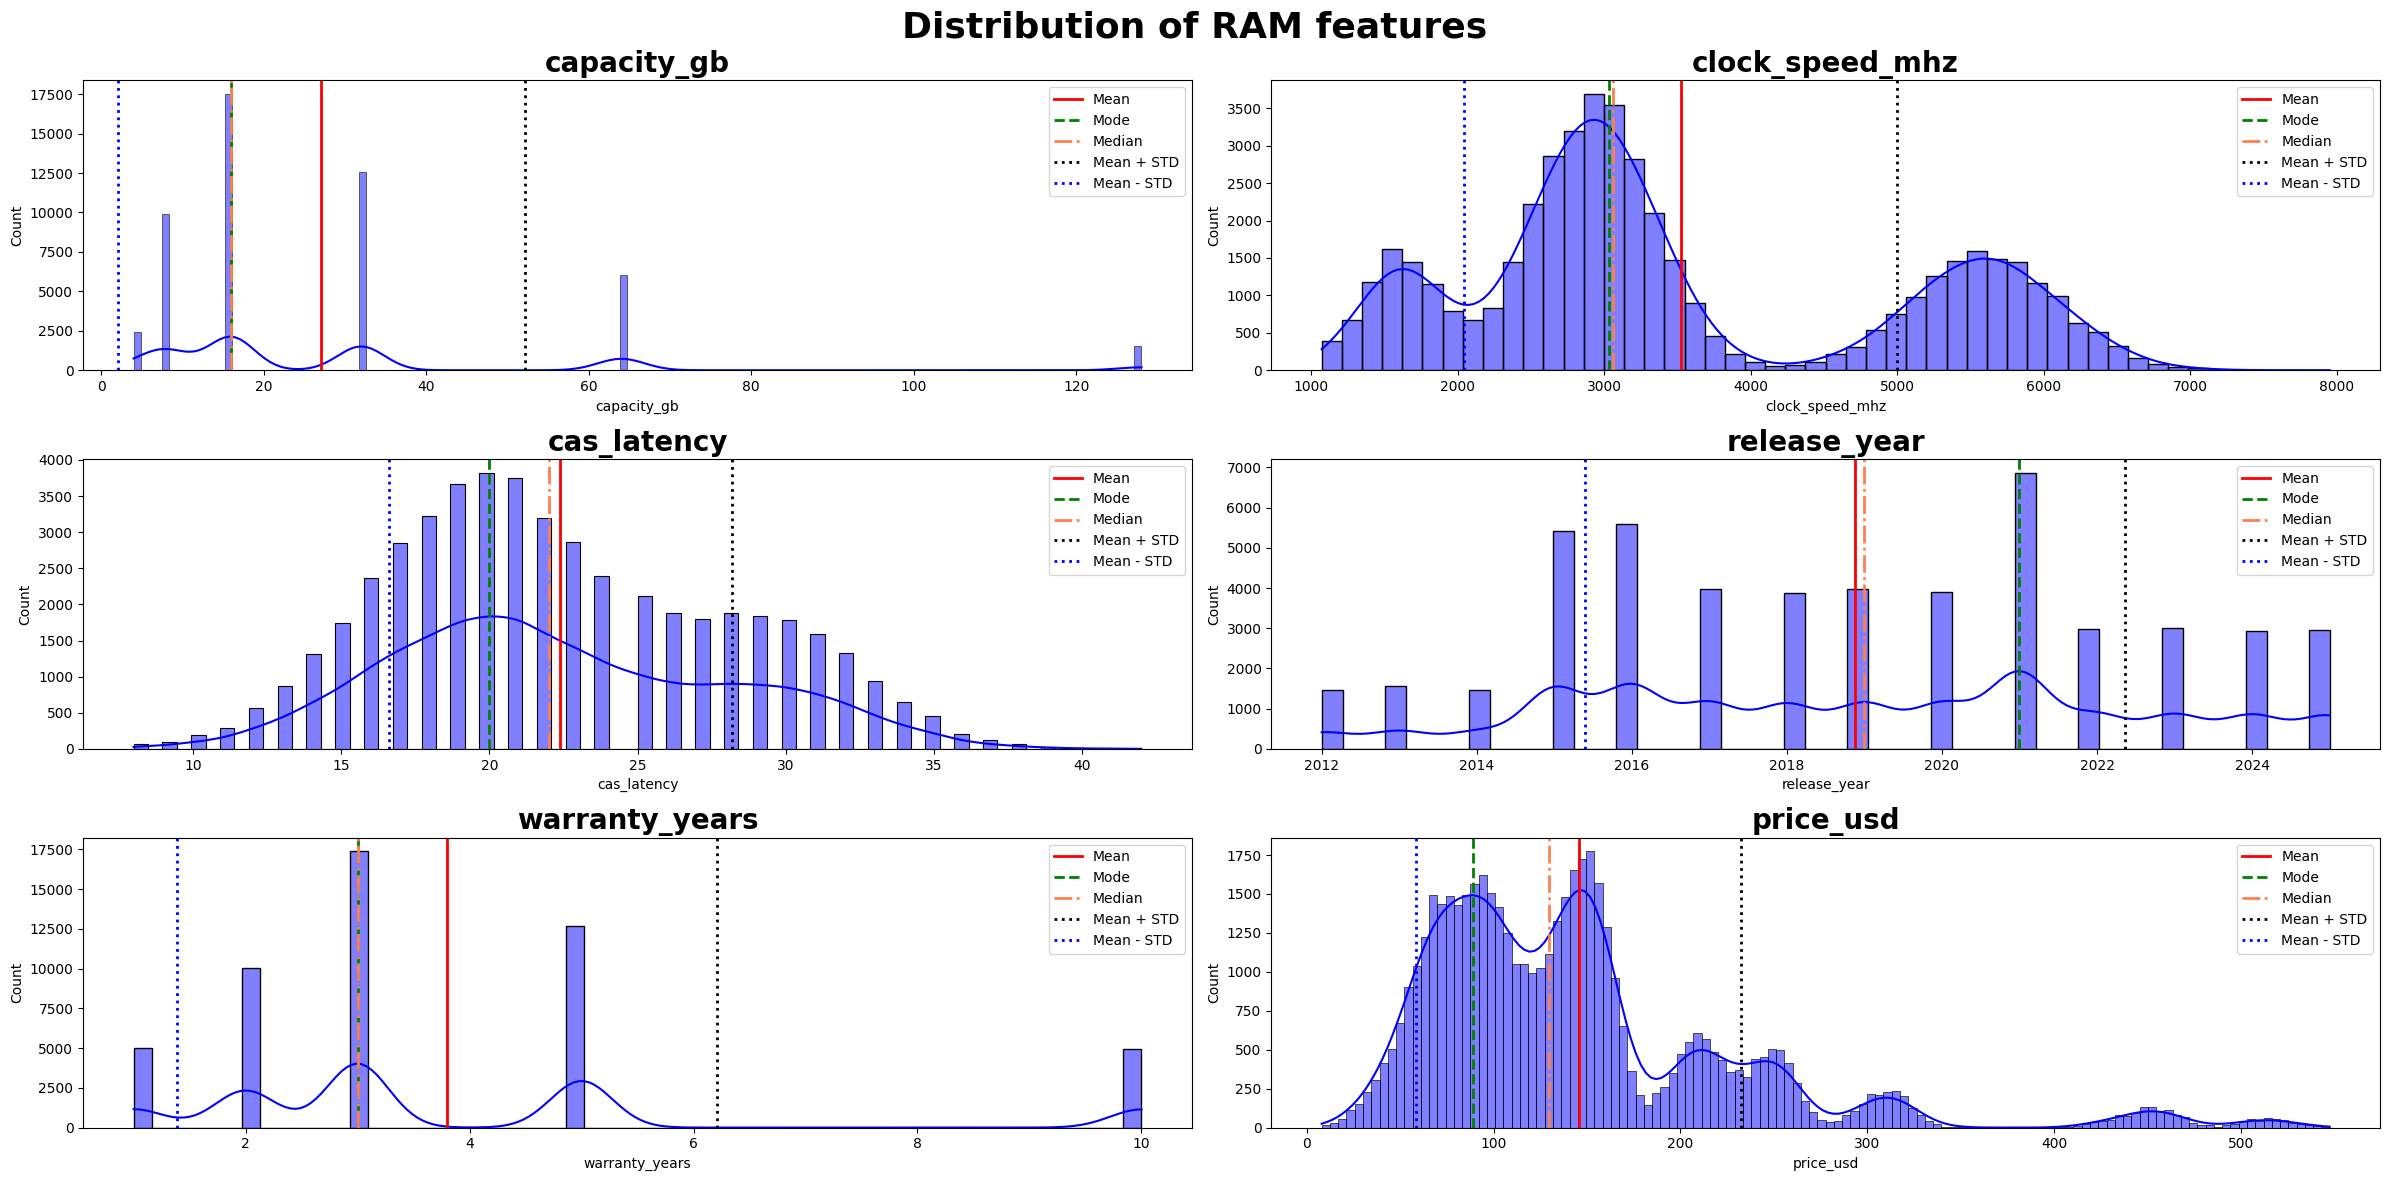

In [ ]:
def plot_numeric_distributions(df, columns, n_cols=2):
    """
    Строит распределения числовых признаков с помощью гистограмм и KDE-кривых

    Параметры:
    df : pandas.DataFrame
        датафрейм, содержащий числовые признаки для анализа

    columns : list
        список названий числовых признаков, для которых необходимо построить распределения

    n_cols : int, по умолчанию 2
        количество графиков в одной строке

    Что рассчитывается:
    для каждого числового признака рассчитываются:
        - среднее значение (Mean);
        - мода (Mode);
        - медиана (Median);
        - стандартное отклонение (STD).

    Что строится:
    для каждого признака строится:
        - гистограмма распределения значений;
        - KDE-кривая плотности;
        - вертикальная линия среднего значения;
        - вертикальная линия моды;
        - вертикальная линия медианы;
        - границы Mean + STD и Mean - STD."""

    # рассчитываем количество строк графиков
    n_rows = (len(columns) + n_cols - 1) // n_cols

    # создаем общую область для всех графиков
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(24, 4 * n_rows))

    # приводим axes к одномерному массиву, что позволяет одинаково работать с любым количеством графиков
    axes = np.atleast_1d(axes).flatten()

    # строим график для каждого числового признака
    for ax, col in zip(axes, columns):
        # рассчитываем основные статистические показатели
        mean = df[col].mean()
        mode = df[col].mode().iloc[0]
        median = df[col].median()
        std = df[col].std()

        # строим гистограмму и KDE-кривую распределения
        sns.histplot(
            data=df,
            x=col,
            kde=True,
            color='blue',
            ax=ax)

        # описываем статистические линии: значение, цвет, стиль линии, название
        lines = [
            (mean, 'red', '-', 'Mean'),
            (mode, 'green', '--', 'Mode'),
            (median, 'coral', '-.', 'Median'),
            (mean + std, 'black', ':', 'Mean + STD'),
            (mean - std, 'blue', ':', 'Mean - STD')]

        # добавляем вертикальные линии на график
        for value, color, linestyle, label in lines:
            ax.axvline(
                value,
                color=color,
                linestyle=linestyle,
                linewidth=2,
                label=label)

        # настраиваем заголовок графика
        ax.set_title(
            col,
            fontsize=20,
            fontweight='bold')

        # добавляем легенду
        ax.legend()

    # удаляем пустые графики, если количество признаков не кратно n_cols
    for ax in axes[len(columns):]:
        fig.delaxes(ax)

    # добавляем общий заголовок
    fig.suptitle(
        'Distribution of RAM features',
        fontsize=26,
        fontweight='bold')

    # автоматически регулируем расположение элементов
    plt.tight_layout()

    # отображаем графики
    plt.show()

plot_numeric_distributions(df_, num)

<font size="4">

Анализ распределений числовых признаков

Большинство числовых признаков имеют дискретное или мультимодальное распределение, поэтому нормальное распределение для них не характерно
- `capacity_gb` и `release_year` имеют выраженный дискретный характер
- `clock_speed_mhz` имеет несколько отчетливых групп значений, что указывает на мультимодальность распределения
- `cas_latency` имеет относительно сглаженное распределение с некоторой правосторонней асимметрией
- `warranty_years` является дискретным признаком с концентрацией наблюдений на отдельных значениях
- `price_usd` имеет выраженное мультимодальное распределение и правый хвост, то есть цены распределены неравномерно

Таким образом, распределения признаков далеки от нормального, но линейная регрессия не требует нормальности признаков (предпосылки касаются остатков), поэтому преобразовывать их ради нормальности не требуется. Мультимодальность, похоже, объясняется смесью поколений памяти и уровней объема это можно проверить на графиках зависимости от цены

</font>

### Распределение у категориальных признаков

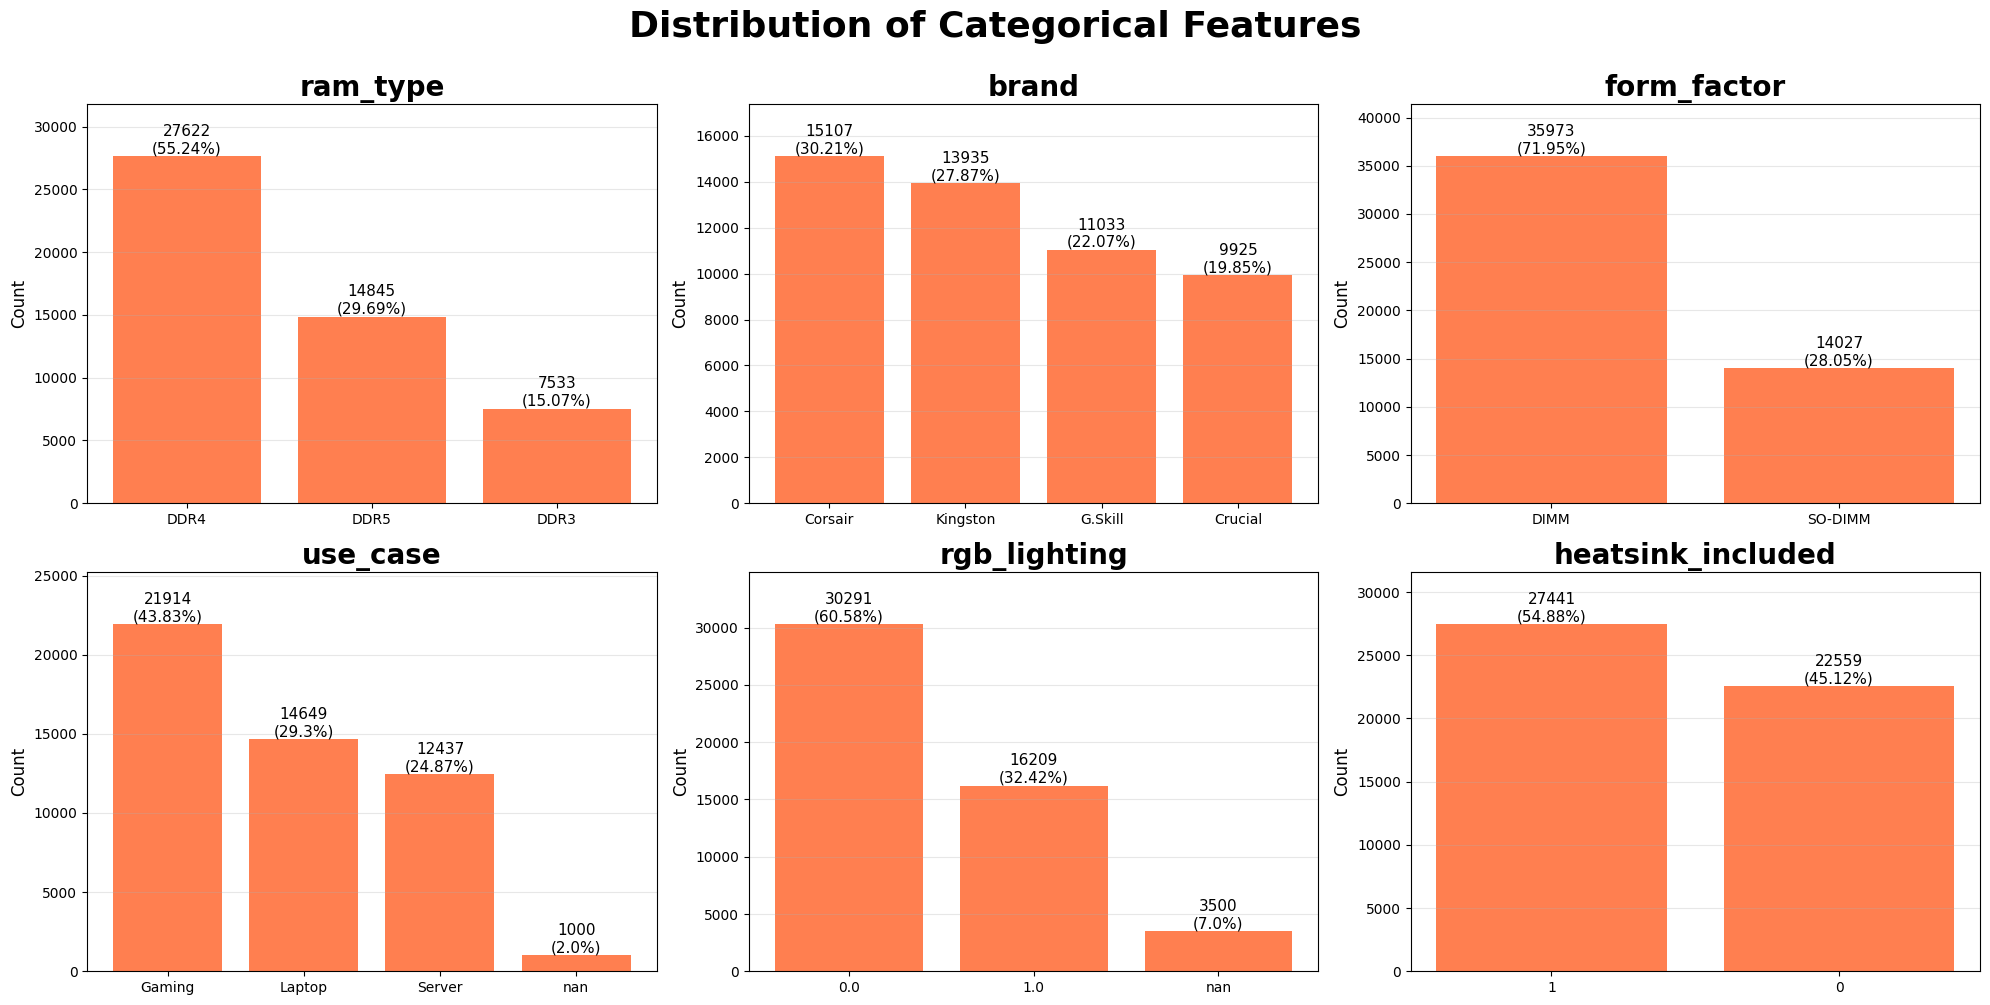

In [ ]:
def plot_categorical_distributions(df, columns, title=''):
    """
    Строит распределения категориальных признаков с помощью столбчатых диаграмм (barplot)

    Параметры:
    df : pandas.DataFrame
        датафрейм, содержащий категориальные признаки для анализа

    columns : list
        список названий категориальных (в том числе бинарных) признаков,
        для которых необходимо построить распределения

    title : str, по умолчанию ''
        общий заголовок для всех построенных графиков

    Что рассчитывается:
    для каждого категориального признака рассчитываются:
        - количество наблюдений в каждой категории (Count);
        - доля каждой категории от общего числа наблюдений в процентах (Percent)

    Что строится:
    для каждого признака строится:
        - столбчатая диаграмма, где высота столбца — количество наблюдений в категории
        - подпись над каждым столбцом: количество и процент
        - горизонтальная сетка по оси Y для удобства сравнения высот
    Графики располагаются по 3 в строке, пустые ячейки сетки удаляются"""

    # кол-во признаков
    n_cols = len(columns)

    # максимум 3 графика в одной строке
    n_rows = (n_cols + 2) // 3

    # создаем сетку графиков
    fig, ax = plt.subplots(n_rows, 3,figsize=(20, 5 * n_rows))

    # преобразуем axes в одномерный массив
    ax = np.atleast_1d(ax).flatten()

    # строим график для каждого признака
    for i, col in enumerate(columns):

        # количество значений каждой категории
        counts = df[col].value_counts(dropna=False)

        # процент каждой категории
        percents = (df[col].value_counts(normalize=True,dropna=False)
            .mul(100)
            .round(2))

        # позиции столбцов по оси X
        x = np.arange(len(counts))

        # строим barplot через matplotlib
        ax[i].bar(x,counts.values,color='coral')

        # добавляем запас сверху, чтобы подписи count и percent не выходили за график
        max_count = counts.max()

        ax[i].set_ylim(0,max_count * 1.15)

        # заголовок графика
        ax[i].set_title(f'{col}',
            fontsize=20,
            fontweight='bold')

        # подпись оси Y
        ax[i].set_ylabel('Count',
            fontsize=12)

        # названия категорий по оси X
        ax[i].set_xticks(x)

        ax[i].set_xticklabels(counts.index.astype(str),
            rotation=0)

        # Сетка
        ax[i].grid(axis='y',
            alpha=0.3)

        # добавляем count и percent над каждым столбцом
        for j, (count, percent) in enumerate(zip(counts.values,percents.values)):
            ax[i].text(j, count, f'{count}\n({percent}%)',
                ha='center',
                va='bottom',
                fontsize=11)

    # удаляем пустые графики
    for j in range(len(columns), len(ax)):
        fig.delaxes(ax[j])

    # общий заголовок
    plt.suptitle(title,
        fontsize=26,
        fontweight='bold',
        y=1.00)

    plt.tight_layout()
    plt.show()


categorical_for_eda = cat + binary

plot_categorical_distributions(df_, categorical_for_eda, title='Distribution of Categorical Features')

<font size="4">

Анализ распределений категориальных признаков

- `ram_type` распределен неравномерно: преобладает DDR4 (55.35%), далее DDR5 (29.51%) и DDR3 (15.13%)
- Распределение `brand` относительно равномерное, при этом наиболее часто встречается Corsair (30.12%), а реже всего Crucial (19.90%)
- `form_factor` имеет выраженный дисбаланс: DIMM составляет 71.97% наблюдений, SO-DIMM - 28.03%
- Для `use_case` наиболее распространен сценарий Gaming (44.76%), далее Laptop (29.86%) и Server (25.37%)
- `rgb_lighting` распределен неравномерно: 65.06% устройств не имеют RGB-подсветки и 34.94% имеют
- `heatsink_included` является наиболее сбалансированным бинарным признаком: 54.93% - с радиатором и 45.07% - без него

Таким образом, категориальные признаки имеют различную степень сбалансированности, однако представленных наблюдений достаточно для дальнейшего анализа их связи с price_usd

Предварительно, признаки `ram_type`, `brand`, `form_factor` и `use_case` будут преобразованы с помощью OneHotEncoder, а `rgb_lighting` и `heatsink_included` останутся бинарными признаками 0/1

</font>

### Boxplot: таргет по категориальным признакам

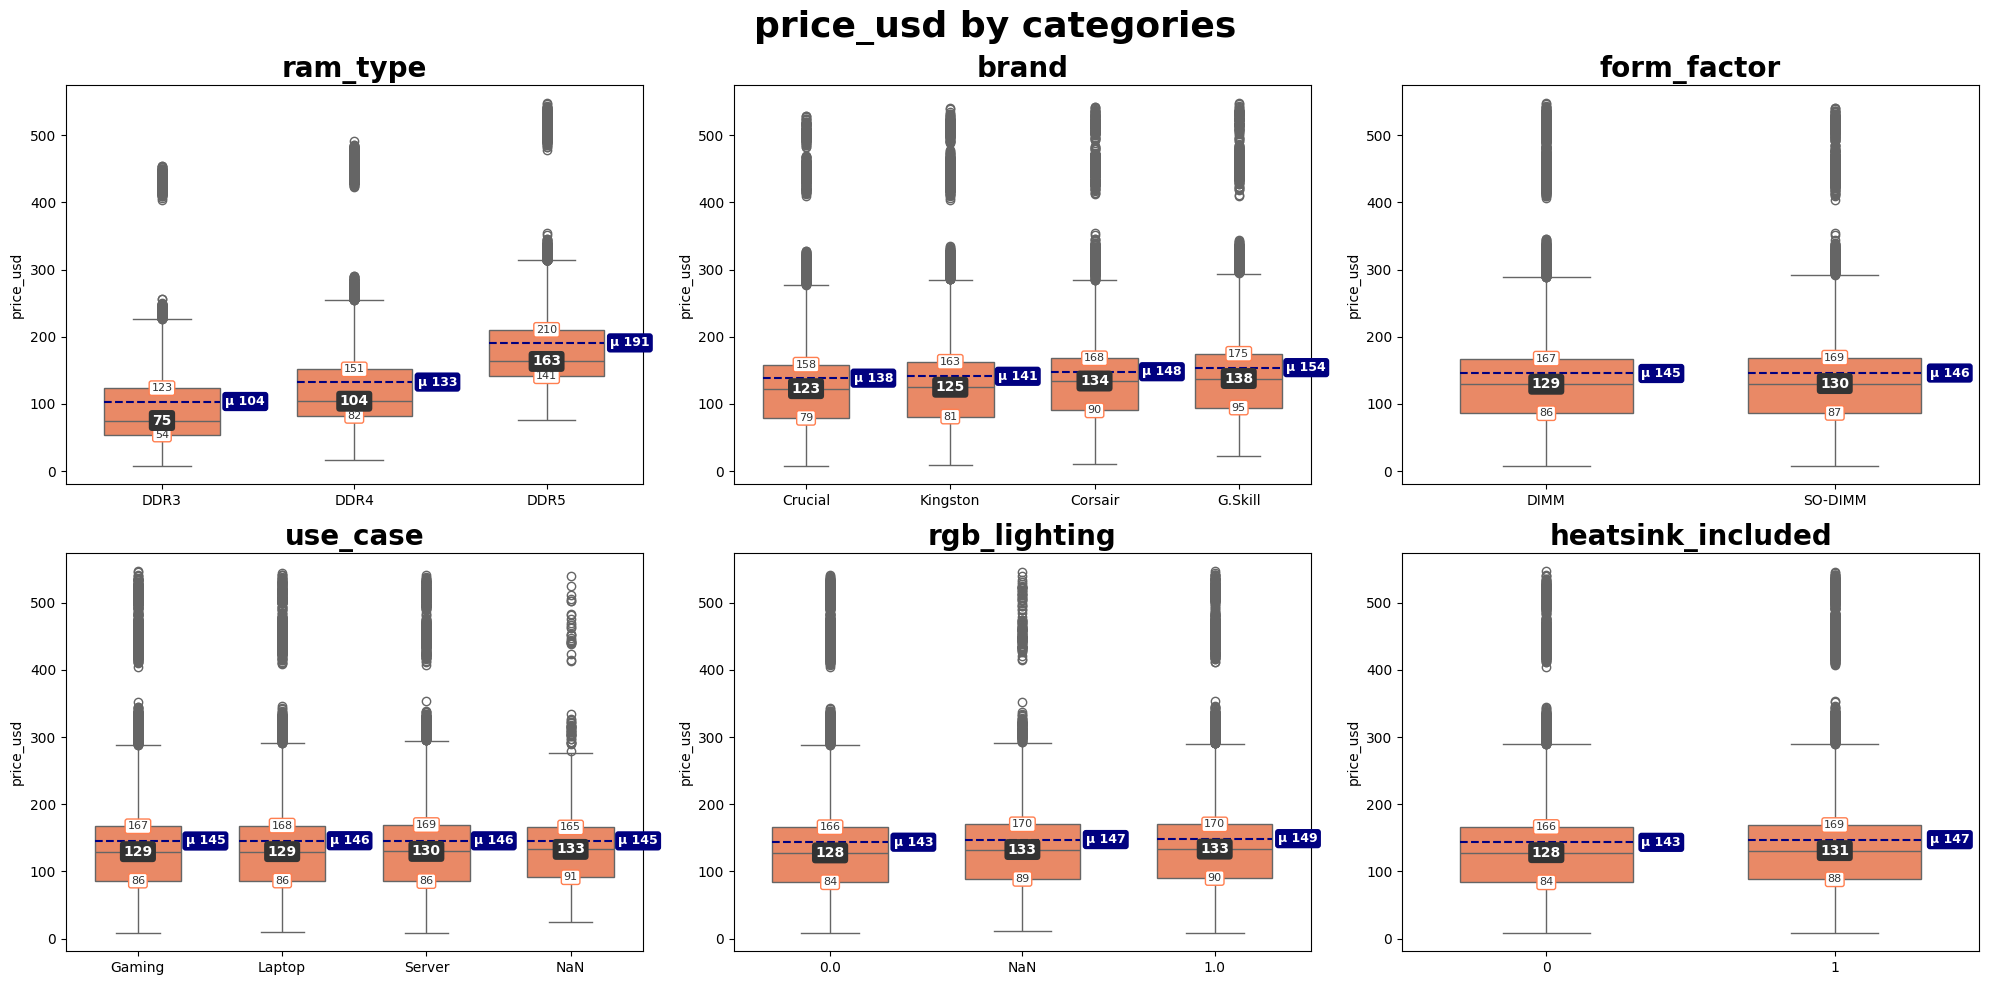

In [ ]:
def plot_target_by_category(df, columns, target='price_usd', n_cols=3, fmt='{:,.0f}'):
    """
    Строит boxplot таргета по категориям каждого признака с подписями медианы, квартилей и среднего прямо на боксах

    Параметры:
    df : pandas.DataFrame
        датафрейм с признаками и таргетом
    columns : list
        категориальные (в том числе бинарные) признаки
    target : str, по умолчанию 'price_usd'
        целевая переменная
    n_cols : int, по умолчанию 3
        количество графиков в одной строке
    fmt : str, по умолчанию '{:,.0f}'
        формат чисел в подписях

    Что строится:
    для каждого признака - boxplot таргета по категориям, пропуски показаны отдельной категорией 'NaN'
    категории упорядочены по медиане таргета
    медиана - тёмная плашка на линии медианы, Q1/Q3 - плашки на границах бокса
    среднее - пунктирная линия и синяя плашка справа от бокса
    """
    n_rows = (len(columns) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    box_width = 0.6

    # стили плашек
    median_style = dict(fontsize=10, fontweight='bold', color='white',
                        bbox=dict(boxstyle='round,pad=0.25', fc='#333333', ec='none'))
    quart_style = dict(fontsize=8, color='#333333',
                       bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='coral', lw=1))
    mean_style = dict(fontsize=9, fontweight='bold', color='white',
                      bbox=dict(boxstyle='round,pad=0.25', fc='navy', ec='none'))

    for ax, col in zip(axes, columns):
        data = df[[col, target]].copy()
        data[col] = data[col].astype(str).replace({'nan': 'NaN'})

        stats = data.groupby(col)[target].agg(
            q1=lambda s: s.quantile(0.25),
            median='median',
            q3=lambda s: s.quantile(0.75),
            mean='mean',
        ).sort_values('median')
        order = stats.index

        sns.boxplot(
            data=data, x=col, y=target, order=order, color='coral', ax=ax,
            width=box_width,
            showmeans=True, meanline=True,
            meanprops={'color': 'navy', 'linestyle': '--', 'linewidth': 1.5},)

        for i, (_, r) in enumerate(stats.iterrows()):
            # Q1 и Q3 - по центру нижней и верхней границы бокса
            ax.text(i, r['q1'], fmt.format(r['q1']), ha='center', va='center', zorder=10, **quart_style)
            ax.text(i, r['q3'], fmt.format(r['q3']), ha='center', va='center', zorder=10, **quart_style)
            # медиана - по центру линии медианы
            ax.text(i, r['median'], fmt.format(r['median']), ha='center', va='center', zorder=11, **median_style)
            # среднее - справа от бокса на уровне пунктирной линии
            ax.text(i + box_width / 2 + 0.03, r['mean'], f"μ {fmt.format(r['mean'])}",
                    ha='left', va='center', zorder=10, **mean_style)

        ax.set_title(col, fontsize=20, fontweight='bold')
        ax.set_xlabel('')

    for ax in axes[len(columns):]:
        fig.delaxes(ax)

    fig.suptitle(f'{target} by categories', fontsize=26, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_target_by_category(df_, cat + binary)

<font size="4">

- `ram_type` - сильный признак: медианная цена растёт от DDR3 (75) к DDR4 (104) и DDR5 (163)
- `brand` - слабый, но заметный эффект: Crucial и Kingston немного дешевле, Corsair и G.Skill немного дороже (разница медиан между крайними брендами около 15)
- `form_factor` и `use_case` - распределения цены практически совпадают, связи с ценой не видно
- `rgb_lighting` и `heatsink_included` - разница минимальная, несколько долларов в пользу модулей с RGB и радиатором

Во всех признаках среднее выше медианы - распределение цены скошено вправо

Строки с пропусками (`NaN` в `use_case` и `rgb_lighting`) по распределению цены заметно не отличаются от остальных, небольшие сдвиги медианы объясняются малым размером этих групп. Это согласуется с предположением о MCAR
Группа цен 400-550 есть во всех категориях, значит, ни один из этих признаков её не объясняет. При этом её уровень растёт от DDR3 к DDR5 - это отдельный дорогой сегмент, вероятно связанный с другим признаком (например, объёмом памяти), внутри которого тоже действует эффект `ram_type`

</font>

### Scatter: таргет от числовых признаков

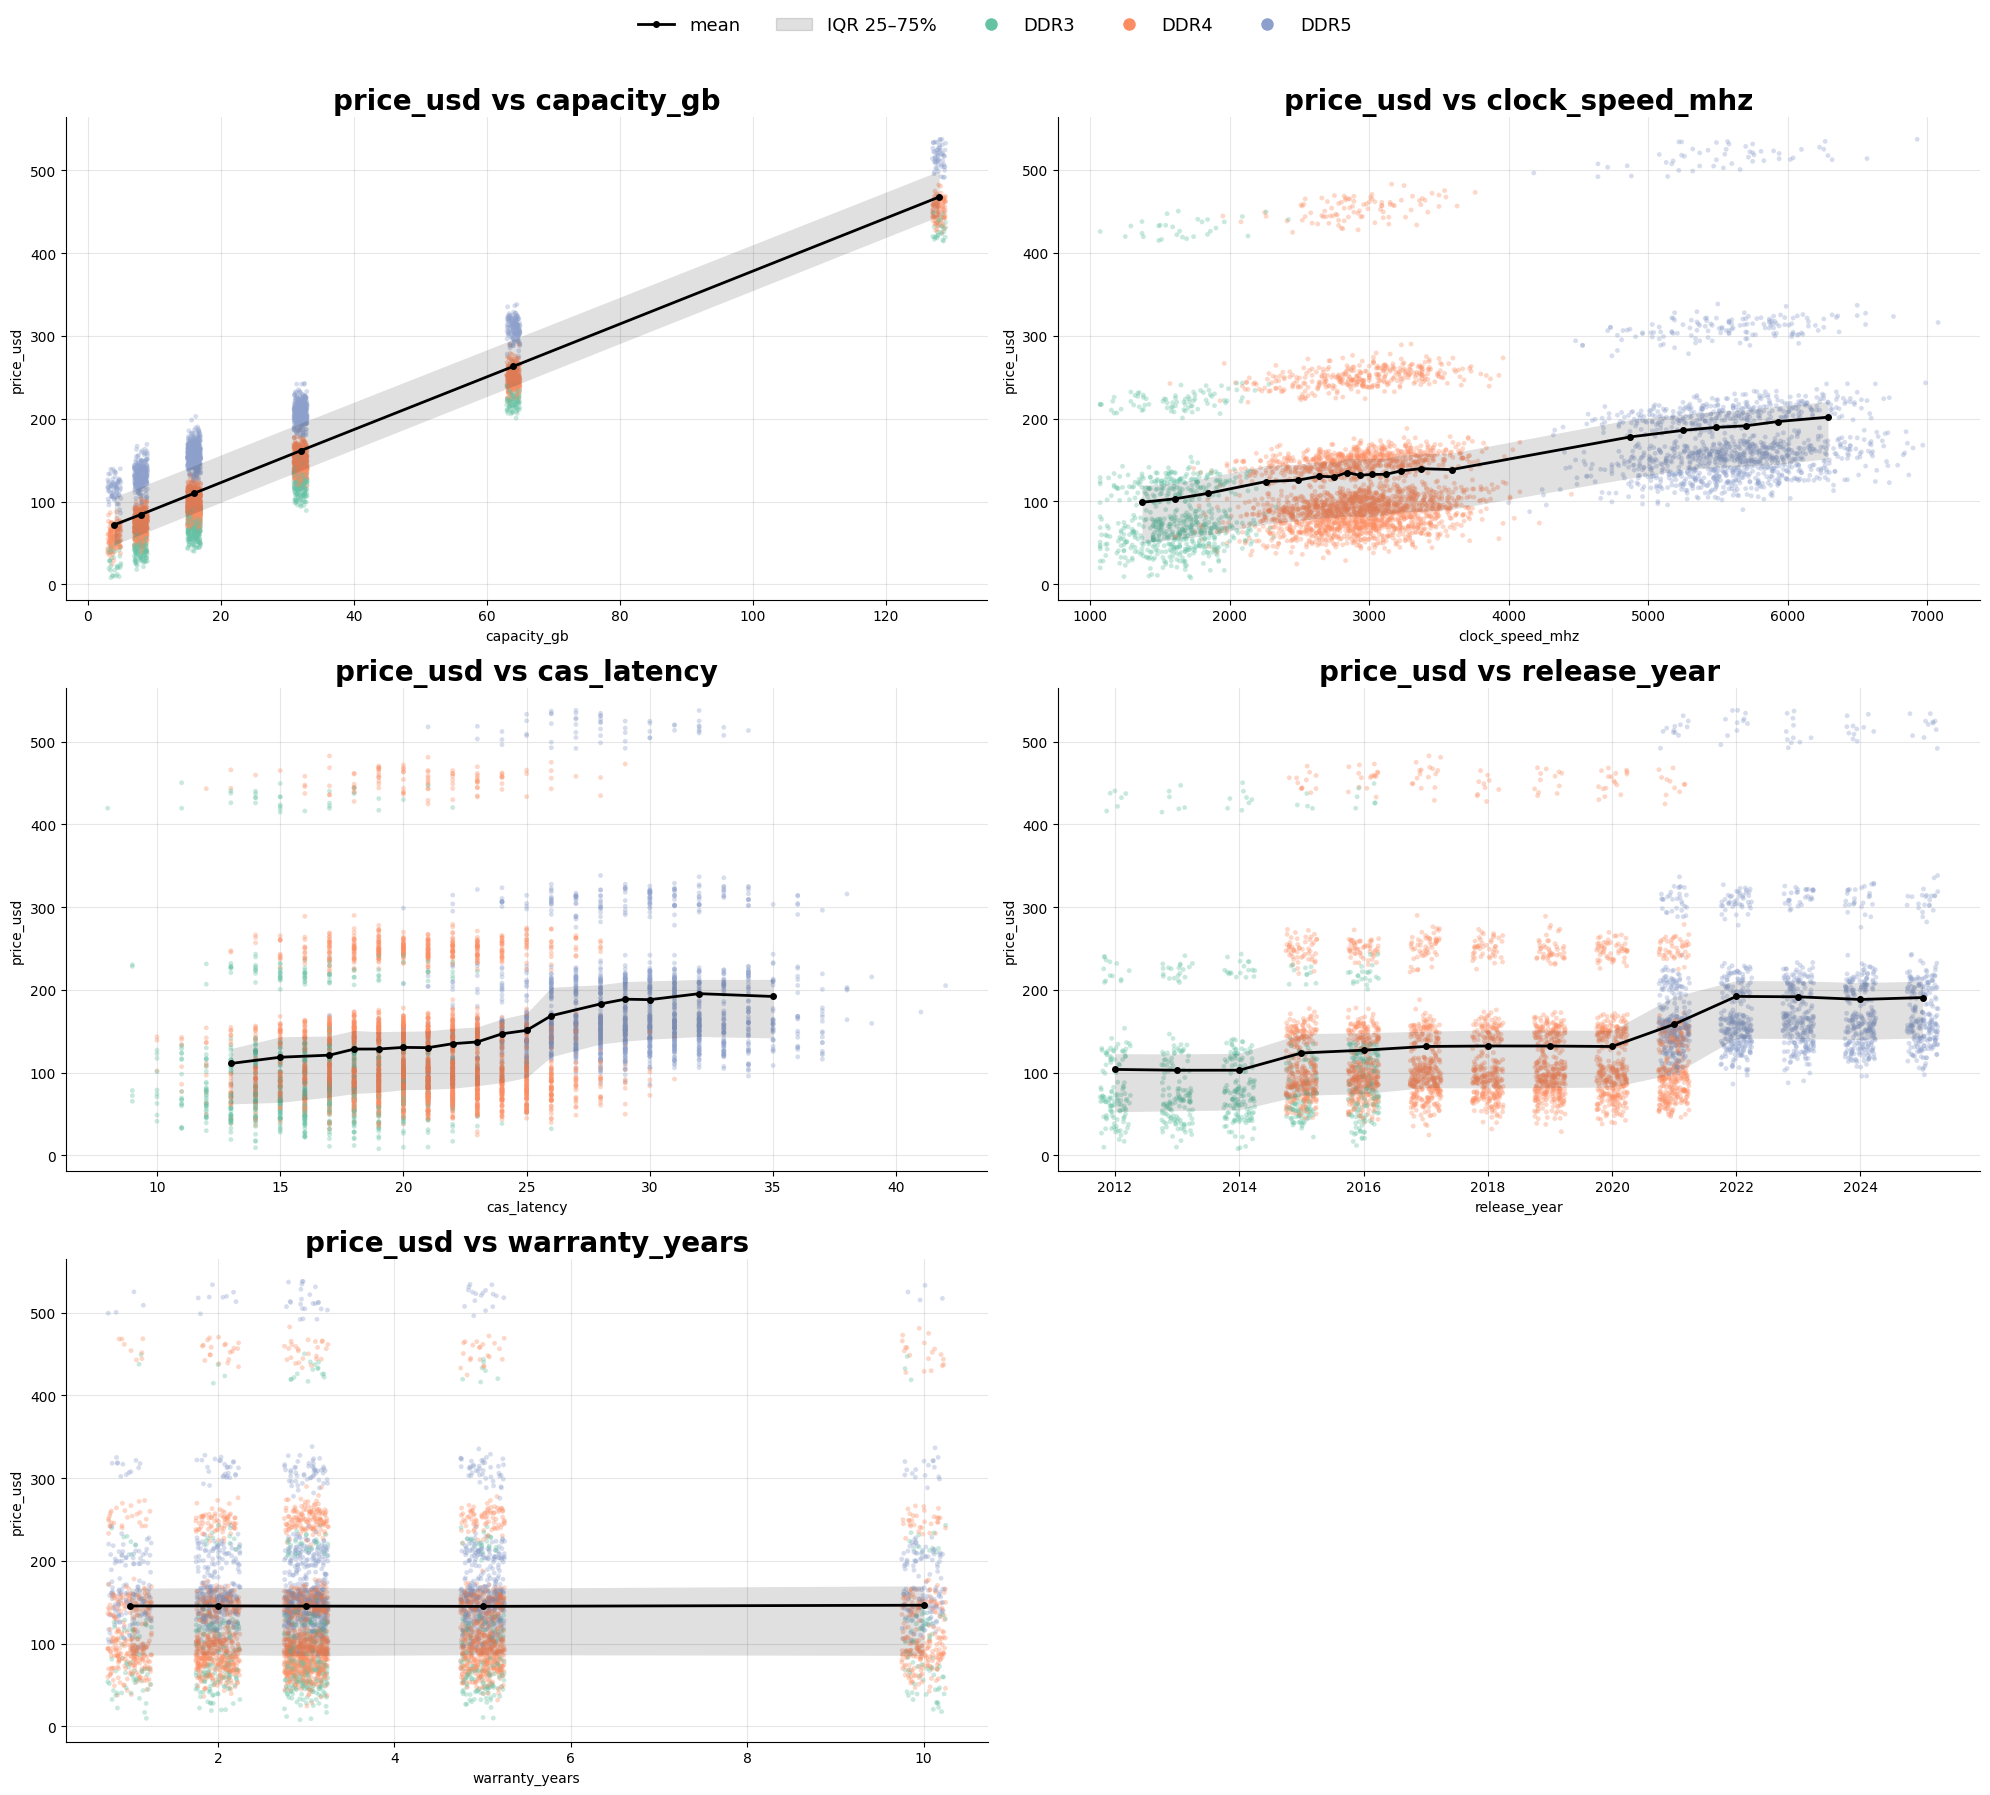

In [ ]:
def plot_target_vs_numeric(df, columns, target='price_usd', hue=None, n_cols=2, sample=5000, max_discrete=30, n_bins=20):
    """
    Строит scatter-графики таргета от числовых признаков с линией тренда

    Параметры:
    df : pandas.DataFrame
        датафрейм с признаками и таргетом
    columns : list
        числовые признаки
    target : str, по умолчанию 'price_usd'
        целевая переменная
    hue : str, по умолчанию None
        признак для раскраски точек (например, 'ram_type')
    n_cols : int, по умолчанию 2
        количество графиков в одной строке
    sample : int, по умолчанию 5000
        сколько случайных строк рисовать: 50 000 точек сливаются в одно пятно
    max_discrete : int, по умолчанию 30
        признак с таким или меньшим числом уникальных значений считается дискретным
    n_bins : int, по умолчанию 20
        число квантильных бинов для тренда у непрерывных признаков

    Что строится:
    для каждого признака - облако точек «признак x таргет» (у дискретных признаков с jitter),
    линия средней цены по значениям признака (или по бинам), полоса 25-75% квантилей
    и коэффициент корреляции Спирмена в углу графика
    """
    n_rows = (len(columns) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 6 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    rng = np.random.default_rng(42)
    data = df.sample(min(sample, len(df)), random_state=42)

    # фиксированная палитра, чтобы цвета категорий совпадали на всех графиках
    palette, hue_order = None, None
    if hue is not None:
        hue_order = sorted(df[hue].dropna().unique())
        palette = dict(zip(hue_order, sns.color_palette('Set2', len(hue_order))))

    for ax, col in zip(axes, columns):
        is_discrete = df[col].nunique() <= max_discrete
        plot_data = data.copy()

        # jitter для дискретных признаков: раздвигаем точки по X, чтобы была видна плотность
        if is_discrete:
            values = np.sort(df[col].dropna().unique())
            step = np.diff(values).min() if len(values) > 1 else 1
            plot_data[col] = plot_data[col] + rng.uniform(-0.25, 0.25, len(plot_data)) * step

        sns.scatterplot(data=plot_data, x=col, y=target,
            hue=hue,
            hue_order=hue_order,
            palette=palette,
            alpha=0.35,
            s=12,
            linewidth=0,
            legend=False,
            ax=ax,)

        # тренд по всем данным: по значениям признака или по квантильным бинам
        trend_src = df[[col, target]].dropna()
        if is_discrete:
            groups = trend_src.groupby(col)[target]
            x_trend = groups.mean().index.values
        else:
            bins = pd.qcut(trend_src[col], q=n_bins, duplicates='drop')
            groups = trend_src.groupby(bins, observed=True)[target]
            x_trend = trend_src.groupby(bins, observed=True)[col].median().values

        ax.fill_between(x_trend, groups.quantile(0.25).values, groups.quantile(0.75).values,
                        color='black', alpha=0.12, linewidth=0, zorder=3)
        ax.plot(x_trend, groups.mean().values, color='black', linewidth=2,
                marker='o', markersize=4, zorder=4)

        ax.set_title(f'{target} vs {col}', fontsize=20, fontweight='bold')
        ax.grid(alpha=0.3)
        ax.set_axisbelow(True)
        sns.despine(ax=ax)

    for ax in axes[len(columns):]:
        fig.delaxes(ax)

    # одна общая легенда для всех графиков
    handles = [Line2D([], [], color='black', lw=2, marker='o', markersize=4, label='mean'), Patch(color='black', alpha=0.12, label='IQR 25–75%')]
    if hue is not None:
        handles += [Line2D([], [], lw=0, marker='o', markersize=8, color=palette[h], label=str(h)) for h in hue_order]
    fig.legend(handles=handles, loc='upper center', ncol=len(handles),
               fontsize=13, frameon=False, bbox_to_anchor=(0.5, 1.0))

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


features = [col for col in num if col != 'price_usd']
plot_target_vs_numeric(df_, features, hue='ram_type')

<font size="4">

- `capacity_gb` - главный признак: цена растёт с объёмом, и линия средней цены почти прямая, от ~ 70 (4 ГБ) до ~ 470 (128 ГБ). Полоса IQR узкая и одинаковой ширины при всех объёмах, полный разброс цены тоже примерно одинаковый (~130), явной гетероскедастичности нет. При одинаковом объёме DDR5 стабильно дороже, а DDR3 дешевле

Горизонтальные «полосы» точек на остальных графиках - это уровни объёма. Цена в первую очередь определяется объёмом, остальные признаки сдвигают её внутри полосы

- `clock_speed_mhz` - три типа памяти занимают разные диапазоны частот (DDR3 ~1000-2000, DDR4 ~2000-4000, DDR5 ~4800-7000 МГц). Внутри каждого типа цена с частотой почти не растёт, а полоса IQR широкая - разброс цены определяется объёмом, а не частотой. Похоже, частота связана с ценой через поколение памяти, а не сама по себе
- `cas_latency` - та же картина: внутри поколения связи с ценой почти нет, общий рост цены с латентностью идёт за счёт DDR5, полоса IQR широкая на всём диапазоне
- `release_year` - средняя цена меняется ступеньками: в 2015 (появление DDR4) и в 2021-2022 (появление DDR5). Внутри периода одного поколения она почти постоянна, вместе с ней ступеньками сдвигается и полоса IQR. Год тоже влияет на цену через поколение
- `warranty_years` - линия средней цены и полоса IQR горизонтальные и одинаковые при любом сроке гарантии, связи с ценой не видно

Частота, латентность и год, судя по графикам, отражают одно и то же - поколение памяти. Это сигнал возможной мультиколлинеарности, проверим её дальше через корреляцию и VIF

Так как зависимость цены от объёма линейная, а разброс постоянный, правая асимметрия цены объясняется распределением `capacity_gb`

</font>

### Доп. графики (интересно посмотреть)

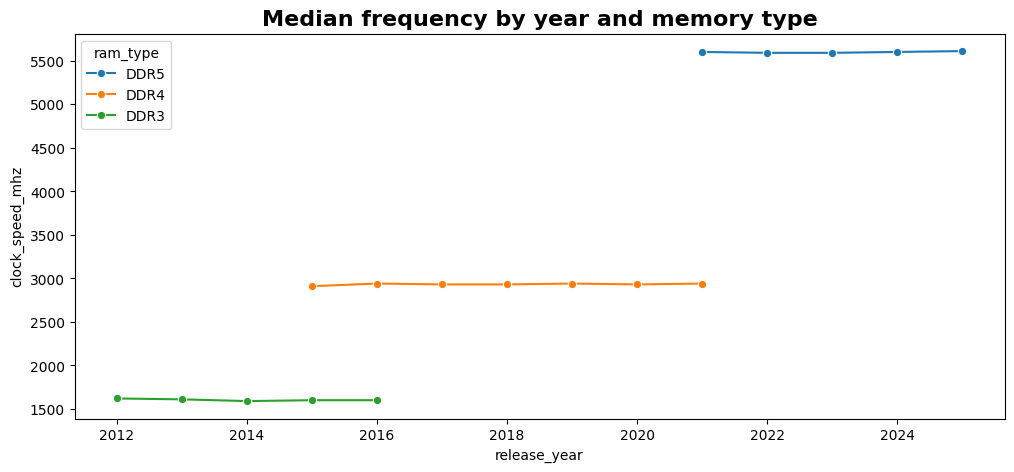

In [ ]:
plt.figure(figsize=(12, 5))
# медианная частота для каждого года, отдельной линией для каждого типа памяти
sns.lineplot(data=df_, x='release_year', y='clock_speed_mhz',
             hue='ram_type',
             estimator='median',
             errorbar=None,
             marker='o')
plt.title('Median frequency by year and memory type', fontsize=16, fontweight='bold')
plt.show()

<font size="4">

Внутри каждого поколения медианная частота по годам практически не меняется: DDR3 ~1600 МГц (2012-2016), DDR4 ~2930 МГц (2015-2021), DDR5 ~5600 МГц (2021-2025)

Частота определяется только типом памяти. Если между частотой и годом есть связь, она возникает из за смены поколений, а не из за роста частоты внутри поколения

Поколения пересекаются по годам: в 2015-2016 выпускались и DDR3, и DDR4, в 2021 - и DDR4, и DDR5

Вывод для импутации: группировка по `release_year` не добавляет информации, поэтому пропуски `clock_speed_mhz` можно заполнять медианой по `ram_type`

</font>

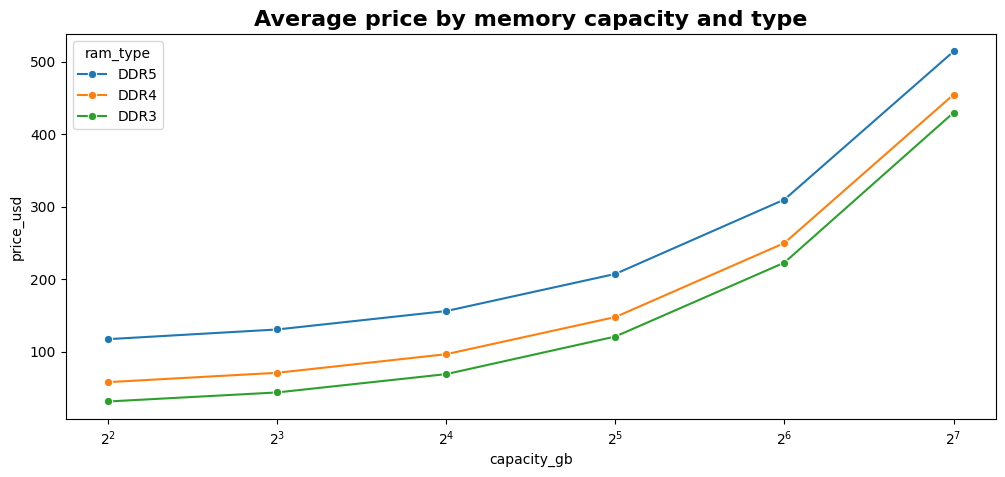

In [ ]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_, x='capacity_gb', y='price_usd',
             hue='ram_type',
             estimator='mean',
             errorbar=None,
             marker='o')
# шаг 4 -> 8 -> 16 -> … => становится равномерным
plt.xscale('log', base=2)
plt.title('Average price by memory capacity and type', fontsize=16, fontweight='bold')
plt.show()

<font size="4">

- Линии не пересекаются при любом объёме DDR5 дороже DDR4 примерно на 59, а DDR4 дороже DDR3 примерно на 27. Тип памяти добавляет к цене фиксированную надбавку и не меняет стоимость гигабайта, поэтому признак-взаимодействие `capacity_gb x ram_type` не нужен
- Прирост цены удваивается при каждом удвоении объёма (+13, +25, +51, +102, +205). Значит, цена растёт линейно по самому `capacity_gb`, примерно на 3.2 за гигабайт. Изгиб линий возникает только из-за логарифмической шкалы по оси X

Поэтому `capacity_gb` оставляем в исходном виде: переход к log2, который предлагался после `describe()`, сломал бы линейную зависимость

</font>

## 5.Статистический анализ

### Корреляция

In [ ]:
cm = sns.color_palette("vlag", as_cmap=True)

df_[num].corr().style \
    .background_gradient(cmap=cm, vmin=-1, vmax=1) \
    .set_properties(**{
        'width': '100px',
        'height': '50px',
        'font-size': '14pt',
        'text-align': 'center'
    })

,capacity_gb,clock_speed_mhz,cas_latency,release_year,warranty_years,price_usd
capacity_gb,1.000000,-0.002255,-0.001122,-0.002724,0.003103,0.922329
clock_speed_mhz,-0.002255,1.000000,0.853159,0.819510,-0.004011,0.361420
cas_latency,-0.001122,0.853159,1.000000,0.700707,-0.002899,0.297816
release_year,-0.002724,0.819510,0.700707,1.000000,-0.002633,0.304869
warranty_years,0.003103,-0.004011,-0.002899,-0.002633,1.000000,0.002081
price_usd,0.922329,0.361420,0.297816,0.304869,0.002081,1.000000


<font size="4">

Корреляция с таргетной переменной `price_usd`

- `capacity_gb` - 0.922 => очень сильная положительная связь
- `clock_speed_mhz` - 0.361 => умеренная положительная связь
- `release_year` - 0.305 => умеренно слабая положительная связь
- `cas_latency` - 0.298 => слабая положительная связь
- `warranty_years` - 0.002 => отсутствует

Основные выводы

- `capacity_gb` - главный коррелирующий с ценой признак: `r = 0.922`.
  Чем больше объем памяти, тем выше цена.
- `clock_speed_mhz`, `release_year` и `cas_latency` имеют умеренную положительную связь с ценой.
- `warranty_years` практически не связан линейно с ценой.

Сама по себе сильная корреляция не означает причинность: высокая связь `capacity_gb` и `price_usd` не доказывает, что увеличение объема само по себе вызывает рост цены (но мы то знаем, что это не так). А вот связь частоты, латентности и года с ценой, судя по scatter-графикам, идёт через поколение памяти (`ram_type`), а не напрямую

Особенно заметна связь:

- `clock_speed_mhz` <=> `cas_latency`: 0.853
- `clock_speed_mhz` <=> `release_year`: 0.820
- `cas_latency` <=> `release_year`: 0.701

Это указывает на мультиколлинеарность между частью признаков. При построении линейной регрессии их совместное влияние на цену может быть трудно разделить

Итог:

Цена в данном датасете прежде всего связана с объемом (`capacity_gb`), затем с `clock_speed_mhz`, `release_year` и `cas_latency`.

<font/>

### Мультиколлениарность (VIF)

In [ ]:
def calculate_vif(df, num_cols, cat_cols=None):
    """
    Рассчитывает VIF (Variance Inflation Factor) для признаков

    VIF_i = 1 / (1 - R^2_i), где R^2_i — коэффициент детерминации регрессии i-го признака
    на все остальные. Показывает, во сколько раз дисперсия коэффициента при признаке
    в линейной регрессии больше, чем была бы без мультиколлинеарности

    Параметры:
    df : pandas.DataFrame
        датафрейм с признаками
    num_cols : list
        числовые признаки (таргет сюда не передаем)
    cat_cols : list, по умолчанию None
        категориальные признаки; переводятся в dummy (drop_first=True), как это будет в модели

    Возвращает:
    pandas.DataFrame
        признак и его VIF, отсортировано по убыванию VIF

    Интерпретация:
    ~1     - мультиколлинеарности практически нет
    1-5    - обычно приемлемо
    5-10   - заметная мультиколлинеарность
    >10    - сильная мультиколлинеарность
    """
    # строки с пропусками убираем: VIF не умеет работать с NaN
    data = df[num_cols + (cat_cols or [])].dropna()

    # категориальные признаки переводим в dummy; первую категорию убираем, чтобы dummy не были идеально коллинеарны
    data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=float)

    # variance_inflation_factor не добавляет свободный член сам, без него VIF завышается
    data = add_constant(data)

    # считаем VIF для каждого столбца по очереди
    vif = pd.DataFrame({
        'feature': data.columns,
        'VIF': [variance_inflation_factor(data.values, i) for i in range(data.shape[1])],
    })

    # VIF для константы не интерпретируется, убираем ее
    vif = vif[vif['feature'] != 'const']

    return vif.sort_values('VIF', ascending=False).reset_index(drop=True)


features_for_vif = [col for col in num if col != 'price_usd']

# 1) только числовые признаки
display(calculate_vif(df_, features_for_vif))

# 2) как признаки попадут в модель: числовые + dummy для ram_type
display(calculate_vif(df_, features_for_vif, cat_cols=['ram_type']))

,feature,VIF
0,clock_speed_mhz,5.694097
1,cas_latency,3.674963
2,release_year,3.045138
3,warranty_years,1.000026
4,capacity_gb,1.000019


,feature,VIF
0,ram_type_DDR5,26.943122
1,clock_speed_mhz,15.464601
2,ram_type_DDR4,5.893167
3,release_year,3.919837
4,cas_latency,3.675020
5,capacity_gb,1.000144
6,warranty_years,1.000049


<font size="4">

Вывод по корреляции и мультиколлинеарности

- `capacity_gb` - главный признак (`r = 0.922` с ценой) и не связан с остальными (VIF = 1.00), исключать его не нужно.
- `warranty_years` ни с чем не связан (VIF = 1.00).
- По числовым признакам мультиколлинеарность умеренная: VIF у `clock_speed_mhz` = 5.69, `cas_latency` = 3.67, `release_year` = 3.05.
- После добавления dummy `ram_type`, как признаки попадут в модель, VIF у `clock_speed_mhz` вырастает до 15.46, а у `ram_type_DDR5` - до 26.94. Частота почти полностью определяется поколением памяти, поэтому эти признаки скорее дублируют друг друга, что для линейной модели грустно, т.к. она не сможет надежно разделить их вклад в цену, `cas_latency` и `release_year` при этом почти не меняются (3.68 и 3.92).

Вывод: сильная мультиколлинеарность сосредоточена в паре `clock_speed_mhz` x `ram_type`

</font>

### Групповые сравнения цены и не только

In [ ]:
# цена за гигабайт assign возвращает копию с новой колонкой, df_ не меняется
(df_.assign(price_per_gb = df_['price_usd'] / df_['capacity_gb'])
    .pivot_table(index='capacity_gb', columns='ram_type', values='price_per_gb', aggfunc='median')
    .round(2))

ram_type,DDR3,DDR4,DDR5
capacity_gb,,,
4,7.92,14.48,29.22
8,5.46,8.82,16.33
16,4.31,6.02,9.75
32,3.78,4.62,6.48
64,3.48,3.90,4.85
128,3.35,3.55,4.02


<font size="4">

Гигабайт заметно дешевеет с ростом объема: у DDR5 от 29.22 за ГБ (4 ГБ) до 4.02 (128 ГБ), у DDR3 - от 7.92 до 3.35

Причина видна на графике: цена модуля складывается из фиксированной части, которая зависит от поколения памяти, но не от объема, и переменной части ~3.2 за ГБ. В маленьких модулях фиксированная часть составляет большую долю цены, поэтому гигабайт в них дороже. С ростом объема цена за ГБ у всех поколений стремится к ~3.2

</font>

In [ ]:
price_pivot = df_.pivot_table(index='capacity_gb', columns='ram_type', values='price_usd', aggfunc='mean')

# переплата за DDR5 по сравнению с DDR4: в долларах и в процентах
premium = pd.DataFrame({
    'DDR5 - DDR4, $': (price_pivot['DDR5'] - price_pivot['DDR4']).round(1),
    'DDR5 - DDR4, %': ((price_pivot['DDR5'] / price_pivot['DDR4'] - 1) * 100).round(1),
})
premium

,"DDR5 - DDR4, $","DDR5 - DDR4, %"
capacity_gb,,
4,59.3,102.3
8,59.7,84.4
16,59.5,61.7
32,59.5,40.3
64,60.0,24.0
128,59.5,13.1


<font size="4">

Переплата за DDR5 по сравнению с DDR4 постоянна в долларах - ~59.5 при любом объеме, но в процентах падает со 102% (4 ГБ) до 13% (128 ГБ). Тип памяти добавляет к цене фиксированную надбавку, а не умножает ее, поэтому для дорогих модулей большого объема переход на DDR5 относительно почти незаметен

</font>

In [ ]:
# средняя цена в каждой группе признака -> разница между самой дорогой и самой дешёвой группой
for col in ['capacity_gb', 'ram_type', 'release_year']:
    group_mean = df_.groupby(col)['price_usd'].mean()
    print(f'{col}: средняя цена от {group_mean.min():.0f} до {group_mean.max():.0f}, '
          f'разница {group_mean.max() - group_mean.min():.0f}')

capacity_gb: средняя цена от 72 до 468, разница 396
ram_type: средняя цена от 104 до 191, разница 87
release_year: средняя цена от 103 до 192, разница 89


In [ ]:
# средняя цена по годам отдельно для каждого типа памяти
df_.pivot_table(index='release_year', columns='ram_type', values='price_usd', aggfunc='mean').round(0)

ram_type,DDR3,DDR4,DDR5
release_year,,,
2012,104.0,NaN,NaN
2013,103.0,NaN,NaN
2014,103.0,NaN,NaN
2015,99.0,133.0,NaN
2016,109.0,134.0,NaN
2017,NaN,132.0,NaN
2018,NaN,132.0,NaN
2019,NaN,132.0,NaN
2020,NaN,132.0,NaN


<font size="4">

- Объем важнее: разница средних цен между крайними группами по `capacity_gb` - 396, а по `ram_type` и `release_year` - всего 87 и 89
- Внутри одного поколения средняя цена по годам почти не меняется (DDR3: 99-109, DDR4: 132-134, DDR5: 188-192). Значит, год сам по себе на цену не влияет
- Частота и латентность ведут себя так же: «современность» влияет на цену только через поколение памяти, а `clock_speed_mhz`, `cas_latency` и `release_year` в основном дублируют `ram_type`

</font>

## 6.Pipline обработки данных

### Как будут обрабатываться данные и почему

<font size="4">

| Признак | Пропуски | Обработка | Обоснование |
|:---|:---|:---|:---|
| `id` | нет | удаляется первым шагом Pipeline (`DropColumns`) | служебный идентификатор, не несёт информации о цене; Pipeline удаляет его сам, поэтому новые данные можно подавать в исходном формате |
| `capacity_gb` | нет | StandardScaler | цена растёт линейно по объёму (~3.2 за ГБ), поэтому только масштабируем; log2 или PowerTransformer согнули бы прямую зависимость |
| `clock_speed_mhz` | 4% | медиана по `ram_type` -> StandardScaler | частота определяется поколением памяти и от года внутри поколения не зависит; заполняем своим трансформером `GroupMedianImputer`. Признак дублирует `ram_type` (VIF 15.5), поэтому есть вариант набора признаков без него (для обучения) |
| `cas_latency` | нет | StandardScaler | связан с ценой только через поколение памяти, VIF умеренный (3.7) |
| `release_year` | нет | StandardScaler | ступеньки цены по годам совпадают со сменой поколений, VIF умеренный (3.9) |
| `warranty_years` | нет | StandardScaler | связи с ценой не видно; оставляем в основном варианте |
| `ram_type` | нет | OneHotEncoder (все категории) | сильный признак: тип памяти добавляет к цене фиксированную надбавку |
| `brand` | нет | OneHotEncoder (все категории) | слабый эффект, разница медиан между брендами около 15 |
| `form_factor` | нет | OneHotEncoder (один столбец 0/1) | бинарный признак, связи с ценой не видно |
| `heatsink_included` | нет | OneHotEncoder (один столбец 0/1) | бинарный признак без пропусков, эффект минимальный |
| `use_case` | 2% | пропуск → категория `'Unknown'` -> OneHotEncoder | при MCAR строки с пропуском - случайная смесь сценариев, модель оценит для `Unknown` средний эффект; заполнение модой (Gaming) дало бы неверные метки и размыло бы эффект Gaming |
| `rgb_lighting` | 7% | пропуск -> метка -1 -> OneHotEncoder (0 / 1 / unknown) | заполнение модой дало бы ~1200 неверных меток «без RGB», а -1 как число без кодирования задало бы ложный порядок |
| `price_usd` (таргет) | нет | без преобразований | зависимость от объёма линейная, разброс цены одинаковый при любом объёме, поэтому логарифм не нужен |

Не удаляем:

- Строки с ценами 400-550 - это модули на 128 ГБ, а не ошибки, они лежат на той же прямой «цена-объем», что и остальные данные
- Строки с пропусками - это суммарно ~13% данных

Настройки OneHotEncoder:

- `drop='if_binary'` - у бинарных признаков остается один столбец 0/1, у остальных все категории. Так новая категория, которой не было в train, кодируется одними нулями и не совпадает ни с одной известной (при `drop='first'` новый тип памяти выглядел бы как DDR3)
- `handle_unknown='ignore'` - Pipeline не падает на новой категории, а кодирует ее нулями

</font>

### Разработка

<font size="4">

Разделяем на тренировочную и тестовую выборку, таргет отделяем от признаков

</font>

In [ ]:
X, y = df_.drop(columns = ['price_usd']), df_['price_usd']

# сначала разбиваем, а предобработку обучаем только на train, чтобы статистика test не попали в модель
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'train: {X_train.shape}, test: {X_test.shape}')

train: (40000, 11), test: (10000, 11)


In [ ]:
class DropColumns(BaseEstimator, TransformerMixin):
    """Удаляет служебные столбцы (например, id), если они есть во входных данных"""

    def __init__(self, columns=('id',)):
        self.columns = columns

    def fit(self, X, y=None):
        # запоминаем входные столбцы для get_feature_names_out
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        # errors='ignore' - если id нет, ничего не падает
        return X.drop(columns=list(self.columns), errors='ignore')

    def get_feature_names_out(self, input_features=None):
        return np.asarray([c for c in self.feature_names_in_ if c not in self.columns], dtype=object)

class GroupMedianImputer(BaseEstimator, TransformerMixin):
    """Заполнение пропусков медианой по группе.
    Входные переменные:
    ===========
    target_col: признак, в котором заполняем пропуски
    group_col: признак, по которому группируем
    """

    def __init__(self, target_col='clock_speed_mhz', group_col='ram_type'):
        self.target_col = target_col
        self.group_col = group_col

    def fit(self, X, y=None):
        # медиана для каждой группы, считается только на тех данных, на которых обучаемся (train)
        self.group_medians_ = X.groupby(self.group_col)[self.target_col].median()

        # общая медиана на случай, если в новых данных встретится группа, которой не было в train
        self.global_median_ = X[self.target_col].median()

        # запоминаем названия входных столбцов, они нужны для get_feature_names_out
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        # работаем с копией, чтобы не менять исходные данные
        X = X.copy()

        # для каждой строки берём медиану её группы; неизвестная группа -> общая медиана
        fill_values = X[self.group_col].map(self.group_medians_).fillna(self.global_median_)

        # заполняем только пропуски
        X[self.target_col] = X[self.target_col].fillna(fill_values)
        return X[self.feature_names_in_]


    def get_feature_names_out(self, input_features=None):
        # столбцы не добавляются и не удаляются, поэтому названия на выходе те же, что на входе;
        # этот метод нужен, чтобы у всего Pipeline работал set_output(transform='pandas')
        return self.feature_names_in_

In [ ]:
num_cols = ['capacity_gb', 'clock_speed_mhz', 'cas_latency', 'release_year', 'warranty_years']
cat_cols = ['ram_type', 'brand', 'form_factor', 'use_case', 'heatsink_included']

# числовые признаки: StandardScaler (линейное преобразование, форма зависимости с ценой не меняется)
num_pipe = Pipeline([
    ('scaler', StandardScaler())
])

# категориальные признаки: OneHotEncoder у бинарных признаков (form_factor, heatsink_included) один столбец 0/1, у остальных все категории, поэтому новая категория (все нули) не совпадает ни с одной известной
# handle_unknown='ignore' => не падать, если в test встретится новая категория
# sparse_output=False это обычная матрица вместо разреженной, чтобы удобно смотреть результат
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False))
])

# rgb_lighting вынесен отдельно: он числовой (0.0 / 1.0), и строка 'Unknown' в одном столбце с числами
# сломала бы OneHotEncoder, поэтому пропуск -> -1 как метка «неизвестно», получается 0 / 1 / unknown
rgb_cols = ['rgb_lighting']

rgb_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=-1)),
    ('encoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False))
])

# пайплайн с обработкой всех признаков
preprocessors_all = ColumnTransformer(transformers=[
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols),
    ('rgb', rgb_pipe, rgb_cols),
], verbose_feature_names_out=False)

In [ ]:
pipe_all = Pipeline([
    ('drop_id', DropColumns(columns=('id',))),
    ('clock_imputer', GroupMedianImputer(target_col='clock_speed_mhz', group_col='ram_type')),
    ('preprocessors', preprocessors_all),
])

# на выходе DataFrame с названиями столбцов, вручную через np.hstack собирать грустно
pipe_all.set_output(transform='pandas')

Pipeline(steps=[('drop_id', DropColumns()),
                ('clock_imputer', GroupMedianImputer()),
                ('preprocessors',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['capacity_gb',
                                                   'clock_speed_mhz',
                                                   'cas_latency',
                                                   'release_year',
                                                   'warranty_years']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constan...
                                                                   OneHotEncoder(drop='if_binary',
                                                                                 handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['ram_type', 'brand',
                                                   'form_factor', 'use_case',
                                                   'heatsink_included']),
                                                 ('rgb',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=-1,
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='if_binary',
                                                                                 handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['rgb_lighting'])],
                                   verbose_feature_names_out=False))])

In [ ]:
# обучаем только на train, к test применяем уже обученный
X_train_transformed = pipe_all.fit_transform(X_train)
X_test_transformed = pipe_all.transform(X_test)

print(f'train: {X_train.shape} -> {X_train_transformed.shape}')
print(f'test: {X_test.shape} -> {X_test_transformed.shape}')

train: (40000, 11) -> (40000, 21)
test: (10000, 11) -> (10000, 21)


In [ ]:
X_train_transformed.head()

,capacity_gb,clock_speed_mhz,cas_latency,release_year,warranty_years,ram_type_DDR3,ram_type_DDR4,ram_type_DDR5,brand_Corsair,brand_Crucial,...,brand_Kingston,form_factor_SO-DIMM,use_case_Gaming,use_case_Laptop,use_case_Server,use_case_Unknown,heatsink_included_1,rgb_lighting_-1.0,rgb_lighting_0.0,rgb_lighting_1.0
39087,-0.443620,-0.401014,-0.585484,0.034235,-0.332869,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
30893,0.197982,-0.935081,-0.585484,-0.539575,-0.332869,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
45278,-0.443620,1.336395,1.315018,1.181855,-0.747168,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
16398,0.197982,-0.583543,-0.585484,0.034235,2.567226,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
13653,-0.443620,-1.442107,-1.794895,-1.974100,2.567226,1.0,0.0,0.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
# медианы частоты, которые Pipeline запомнил на train
pipe_all['clock_imputer'].group_medians_

,clock_speed_mhz
ram_type,
DDR3,1600.0
DDR4,2930.0
DDR5,5600.0


### Тестирование

<font size="4">

   Проверяем Pipeline на новых модулях, которых нет в датасете. Данные подаются в исходном виде, без ручного заполнения, кодирования и масштабирования:

   1. обычный модуль DDR4 без пропусков - контрольный объект
   2. DDR5 на 256 ГБ, 2027 года - объем и год вне диапазона train, пропущены частота, `use_case` и `rgb_lighting`
   3. DDR3 нового бренда Patriot, пропущена частота
   4. полностью новые категории: тип DDR6, форм-фактор CAMM2, сценарий Workstation, плюс пропуски частоты и `rgb_lighting`

</font>

In [ ]:
new_ram = pd.DataFrame({
    'id':                [100001,     100002,    100003,    100004],
    'capacity_gb':       [16,         256,       8,         32],
    'clock_speed_mhz':   [3200,       np.nan,    np.nan,    np.nan],
    'cas_latency':       [16,         40,        11,        44],
    'release_year':      [2020,       2027,      2013,      2026],
    'warranty_years':    [3,          10,        1,         5],
    'ram_type':          ['DDR4',     'DDR5',    'DDR3',    'DDR6'],
    'brand':             ['Kingston', 'Corsair', 'Patriot', 'G.Skill'],
    'form_factor':       ['DIMM',     'DIMM',    'SO-DIMM', 'CAMM2'],
    'use_case':          ['Gaming',   np.nan,    'Laptop',  'Workstation'],
    'rgb_lighting':      [1,          np.nan,    0,         np.nan],
    'heatsink_included': [1,          1,         0,         1],
})
new_ram

,id,capacity_gb,clock_speed_mhz,cas_latency,release_year,warranty_years,ram_type,brand,form_factor,use_case,rgb_lighting,heatsink_included
0,100001,16,3200.0,16,2020,3,DDR4,Kingston,DIMM,Gaming,1.0,1
1,100002,256,NaN,40,2027,10,DDR5,Corsair,DIMM,NaN,NaN,1
2,100003,8,NaN,11,2013,1,DDR3,Patriot,SO-DIMM,Laptop,0.0,0
3,100004,32,NaN,44,2026,5,DDR6,G.Skill,CAMM2,Workstation,NaN,1


In [ ]:
# как заполнилась частота
pipe_all['clock_imputer'].transform(new_ram)[['ram_type', 'clock_speed_mhz']]

,ram_type,clock_speed_mhz
0,DDR4,3200.0
1,DDR5,5600.0
2,DDR3,1600.0
3,DDR6,3070.0


In [ ]:
# предупреждение OneHotEncoder о новых категориях - ожидаемо, это не ошибка
new_ram_transformed = pipe_all.transform(new_ram)

print('Пропусков после обработки:', new_ram_transformed.isna().sum().sum())
new_ram_transformed.T.round(2)

Пропусков после обработки: 0


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,0,1,2,3
capacity_gb,-0.44,9.18,-0.76,0.20
clock_speed_mhz,-0.22,1.40,-1.30,-0.31
cas_latency,-1.10,3.04,-1.97,3.73
release_year,0.32,2.33,-1.69,2.04
warranty_years,-0.33,2.57,-1.16,0.50
ram_type_DDR3,0.00,0.00,1.00,0.00
ram_type_DDR4,1.00,0.00,0.00,0.00
ram_type_DDR5,0.00,1.00,0.00,0.00
brand_Corsair,0.00,1.00,0.00,0.00
brand_Crucial,0.00,0.00,0.00,0.00


<font size="4">

Pipeline обработал новые объекты без ошибок, пропусков после преобразования нет. Данные подавались в исходном виде: заполнение, кодирование и масштабирование Pipeline выполнил сам

По объектам:

1. Обычный DDR4 - контрольный объект, закодирован так же, как строки train
2. DDR5 на 256 ГБ 2027 года - пропуск частоты заполнен медианой DDR5 (5600), пропуск `use_case` попал в `use_case_Unknown`, пропуск `rgb_lighting` - в `rgb_lighting_-1.0`. Объем и год вне диапазона train просто масштабированы: `capacity_gb` = 9.18, то есть объем на ~9 стандартных отклонений выше среднего. Ошибки нет, но линейная модель продлит прямую «цена-объем» за пределы известных данных, и такому прогнозу стоит доверять меньше
3. Бренд Patriot - бренда нет в train, поэтому все столбцы `brand_*` равны 0. Пропуск частоты заполнен медианой DDR3 (1600)
4. DDR6 / CAMM2 / Workstation - для DDR6 медианы группы в train нет, поэтому частота заполнена общей медианой (3070). Все столбцы `ram_type_*` и `use_case_*` равны 0: новая категория не выдается ни за одну известную. Исключение - бинарный `form_factor`: при одном столбце `form_factor_SO-DIMM` значение 0 означает DIMM, поэтому CAMM2 выглядит как DIMM

Предупреждения `UserWarning: Found unknown categories` - это не ошибки, а ожидаемое поведение `handle_unknown='ignore'`. OneHotEncoder сообщает о 4 новых категориях: DDR6 (`ram_type`), Patriot (`brand`), CAMM2 (`form_factor`) и Workstation (`use_case`)

</font>

## Выводы

<font size="4">

1. Гигабайт дешевеет с ростом объема. Цена модуля - это фиксированная часть, зависящая от поколения, плюс ~3.2 USD за каждый ГБ. Поэтому у маленьких модулей гигабайт стоит дорого (DDR5 на 4 ГБ - 29 USD за ГБ), а у модулей на 128 ГБ цена за ГБ у всех поколений сходится к 3.4-4.0 USD
2. Переплата за DDR5 постоянна в долларах, но не в процентах. DDR5 дороже DDR4 на ~59.5 USD при любом объеме, а DDR4 дороже DDR3 на ~27 USD. В процентах переплата за DDR5 падает со 102% у модулей на 4 ГБ до 13% у модулей на 128 ГБ
3. Объем важнее "современности". Корреляция объема с ценой 0.92, разница средних цен по объему - 396 USD против 87 по типу памяти и 89 по году. Частота, латентность и год влияют на цену только через поколение: внутри одного поколения цена от них почти не зависит, а частота дублирует `ram_type` (VIF 15.5)
4. Неожиданность: более "медленная" память (выше CAS latency) в среднем дороже. Это ложная связь через поколение у DDR5 латентность в тактах выше, а сам он дороже; внутри поколения связи нет
5. Качество данных: удалено 8000 дубликатов; пропуски в трех признаках согласуются с MCAR и заполняются в Pipeline; цены 400-550 - не выбросы, а модули на 128 ГБ. Ряд признаков ("круглые" доли пропусков, идеально постоянная надбавка за DDR5) указывает на синтетическое происхождение данных, поэтому выводы описывают этот набор данных, а не реальный рынок
6. Pipeline объединяет заполнение пропусков, кодирование и масштабирование в один объект, обучается только на train и без ошибок обрабатывает test и новые модули, включая пропуски, незнакомые категории и значения вне диапазона train
7. Зависимость цены от объёма линейная, а влияние поколения аддитивное, без взаимодействия, поэтому линейная регрессия должна описывать данные хорошо
</font>